# Who Makes Money While Wall Street Sleeps?

*ADA 2026 — Milestone P2: initial analyses.* The full project proposal is in the [README](README.md).

## Introduction

Over the last decades, almost all of the gains of the US stock market seem to have been made **overnight**, between the close and the next open, while the **trading day** itself, when almost all trading, news reaction and price discovery happen, earned close to nothing. If returns reward risk or new information, both halves of the day should earn something. So who makes money while Wall Street sleeps?

We treat this anomaly as an investigation. We first establish the facts in our data (**the crime**), then interrogate three suspects: **risk** (do longer nights pay more?), **news** (do announcements land after the close?) and **the crowd** (does a burst of attention produce an overnight gain followed by an intraday "hangover"?). Tickers that look almost identical to famous ones provide a natural experiment (**the proof**), and the verdict comes in P3.

**Research questions**
1. Do overnight returns exceed intraday returns across US stocks and ETFs, and does the gap survive data cleaning and statistical testing?
2. Risk: do longer market closures (weekends, holidays) earn higher overnight returns?
3. News: are corporate announcements (SEC 8-K filings) concentrated after the close, and do nights without announcements still earn more?
4. Crowd: after an attention spike (abnormal volume, Google Trends), do we observe an overnight gain followed by an intraday loss?
5. Proof: do tickers that are easily mistaken for famous ones show the same pattern, compared with random placebo pairs?

**Roadmap.** Part I - The data · Part II - The crime · Part III - Risk · Part IV - News · Part V - The crowd · Part VI - The proof.

# Part I — The Data

Part I shows that we can handle a dataset of this size, that we understand what is in it, and that every transformation is justified. Every later chapter uses the table produced here.

## I.1 Reproducing the data

- `download_data()`: downloads the raw CSVs from Kaggle into `data/`.
- `build_prices()`: cleans them and writes `data/prices.parquet`.
- `load_prices()`: loads the table used by every chapter.

`data/` is not versioned. First run: ~520 MB download, 1–2 min build.

In [1]:
%load_ext autoreload
%autoreload 2

from src.config import STUDY_START_YEAR
from src.data.load import download_data, build_prices, load_prices
from src.data.metadata import (
    load_metadata, exchange_breakdown, tag_special_etfs, etf_exclusion_counts, exclude_special_etfs,
)
from src.analysis.overview import (
    tickers_per_year, first_dates, size_report, removed_rows_summary, adjustment_example,
    missing_values, return_stats, night_day_correlation, volume_summary, stale_among_zero_volume,
)
from src.visualization.plots import (
    set_style, plot_tickers_per_year, plot_suspicious_share, plot_return_distributions, plot_volume_distribution,
    plot_wealth, plot_wealth_grid, plot_gap_histogram, plot_gap_heatmap, plot_filter_comparison,
)
from src.features.returns import add_returns, add_dollar_volume, portfolio_returns
from src.analysis.crime import (
    ticker_wealth, crime_headline, study_portfolios, portfolio_paths, portfolio_headlines,
    night_day_gap_by_ticker, gap_share_above_zero, gap_heatmap_table, filter_comparison,
    night_indicator_regression, block_bootstrap_ci, label_sample,
)
from src.data.quality import (
    flag_suspicious, suspicious_share_by_year, apply_quality_filter, FILTERS,
    stale_share_by_liquidity, splice_examples, filter_summary, flag_count_by_year,
)

set_style()

from src.features.volume import abnormal_volume
from src.analysis.crowd import event_study, plot_event_study

/Users/rania/Projects/Project_ADA_Stock_Markets_TheAnalysts/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
download_data()
build_prices()
prices = load_prices()

## I.2 Source and format

*Stock Market Dataset* (Oleh Onyshchak, Kaggle): daily prices of all Nasdaq-traded stocks and ETFs, from 1962 to 1 April 2020. One CSV per ticker with `Date, Open, High, Low, Close, Adj Close, Volume`; `Adj Close` is adjusted for splits and dividends. Tickers per listing exchange:

In [3]:
meta = load_metadata()
exchange_breakdown(meta)

,stock,etf,total
exchange,,,
Nasdaq,2988,395,3383
NYSE,2520,0,2520
NYSE Arca,107,1435,1542
Cboe BZX,17,334,351
NYSE American,252,1,253
total,5884,2165,8049


Processed format: one row per (ticker, date). Raw `open` and `close` are kept to detect stale opens (I.6).

In [4]:
display(prices.head())
prices.dtypes

,ticker,date,open,close,open_adj,high_adj,low_adj,close_adj,volume,asset_type
0,A,1999-11-18,32.546494,31.473534,27.991459,30.759848,24.607878,27.068665,62546300,stock
1,A,1999-11-19,30.713520,28.880543,26.415020,26.453470,24.492531,24.838577,15234100,stock
2,A,1999-11-22,29.551144,31.473534,25.415323,27.068665,24.646326,27.068665,6577800,stock
3,A,1999-11-23,30.400572,28.612303,26.145872,26.837971,24.607880,24.607880,5975600,stock
4,A,1999-11-24,28.701717,29.372318,24.684778,25.799820,24.607878,25.261524,4843200,stock


ticker              category
date          datetime64[ns]
open                 float32
close                float32
open_adj             float32
high_adj             float32
low_adj              float32
close_adj            float32
volume                 Int64
asset_type          category
dtype: object

## I.3 Coverage over time

We count, for each year, the number of tickers with at least one trading day, for stocks and ETFs. This shows from which year the cross-section is large enough to support conclusions.

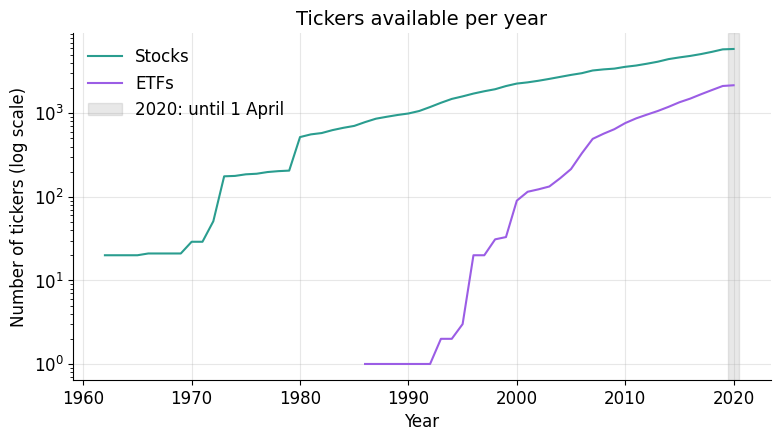

In [5]:
counts = tickers_per_year(prices)
fig = plot_tickers_per_year(counts)

In [6]:
counts.loc[[1962, 1970, 1980, 1990, 2000, 2010, 2019]]

,stock,etf
year,,
1962,20,0
1970,29,0
1980,519,0
1990,994,1
2000,2267,90
2010,3596,763
2019,5818,2121


Dates on which the most tickers have their first observation (many tickers starting on the same day reveal a change in data coverage):

In [7]:
first_dates(prices)

,n_tickers
first_date,
1980-03-17,257
1973-02-21,87
2017-10-26,39
1973-05-03,26
2000-01-03,25


**Takeaway:** Coverage grows from 20 stocks in 1962 to 5,818 in 2019, and ETFs only become numerous after 2000. The jumps in 1973 and 1980 come from the data provider, not from real listings: 87 tickers start on 21 February 1973 and 257 on 17 March 1980. Before the 1980s, cross-sectional results would rely on a few long-surviving firms. The study period is set in I.6 from the quality of opening prices.

**Survivorship bias:** The dataset only contains securities still listed in 2020: firms that went bankrupt, were delisted or were acquired are missing. Long-run average returns are therefore likely biased upwards. This affects both overnight and intraday returns, but we cannot assume it affects them equally.

## I.4 Handling the size

We compare three ways of holding the data: the raw CSVs read with pandas default dtypes, the same CSVs read with optimised dtypes, and the processed Parquet file. CSV memory and loading time are measured on a random sample of 500 files and scaled to all files; the other figures are exact.

In [8]:
size_report()

,rows,memory (GB),loading time (s),disk size (GB)
"CSV, default dtypes",28151758,6.70,32.38,2.75
"CSV, optimised dtypes",28151758,1.13,57.59,2.75
Parquet,28132072,1.24,1.61,0.70


**Choices:** `ticker` and `asset_type` are stored as `category` (a few thousand distinct values repeated millions of times), prices as `float32` (about 7 significant digits, enough for prices) and volume as nullable `Int64`. Parquet is a compressed, column-oriented format that keeps these dtypes and can read only selected columns or tickers. 

**Takeaway:** Optimised dtypes divide memory by about 5 (6.03 GB → 1.13 GB). Parsing dates makes the optimised CSV read slower (about a minute), but it is paid once in `build_prices()`: loading the Parquet file then takes about a second and uses 0.71 GB on disk instead of 2.75 GB. The Parquet table is slightly larger in memory than the optimised CSVs because it also holds the adjusted prices. The difference in row counts (28,151,758 − 28,132,072 = 19,686) is exactly the total of the rows removed in I.6.a.

## I.5 Transformations

Two transformations turn raw prices into the quantities we study: prices are first adjusted for dividends, then split into an overnight and an intraday return.

**Adjusted prices.** In this dataset `Open`, `High`, `Low` and `Close` already account for splits, but not for dividends: on an ex-dividend day the price drops by the dividend, which is not a loss for shareholders. `Adj Close` accounts for both, so we apply its daily factor to the other prices:

$$f_t = \frac{\text{Adj Close}_t}{\text{Close}_t}, \qquad \text{open\_adj}_t = \text{Open}_t \times f_t$$

(same for `high_adj` and `low_adj`; `close_adj` is `Adj Close`). All prices of a day are rescaled by the same factor, so returns within a day are unchanged and returns across an ex-dividend date include the dividend.

Example: Apple went ex-dividend on 7 February 2020. Its overnight return from raw and from adjusted prices:

In [9]:
adjustment_example(prices, ticker="AAPL", date="2020-02-07")

,previous close,open,overnight return (%)
raw,325.21,322.37,-0.87
adjusted,324.44,322.37,-0.64


**Takeaway:** The raw previous close (325.21) exceeds the adjusted one (324.44) by \$0.77, the dividend paid. Without adjustment, the night would show −0.87 % instead of −0.64 %: the dividend would be counted as an overnight loss.

**Overnight and intraday returns**, computed within each ticker:

$$r^{\text{night}}_t = \frac{\text{open\_adj}_t}{\text{close\_adj}_{t-1}} - 1, \qquad r^{\text{day}}_t = \frac{\text{close\_adj}_t}{\text{open\_adj}_t} - 1$$

The night runs from the previous close to the open, the day from the open to the close. $t-1$ is the previous **trading day of the market**, defined as the previous date in the union of all dates present in the table (every day on which at least one ticker traded). If the ticker has no row on that day (first observation, gap, removed row), $r^{\text{night}}_t$ is missing, so a night never hides several days. Weekends and holidays are kept: they are one (long) night.

## I.6 Cleaning and data quality

### I.6.a Rows removed by the pipeline

Rows that cannot be used at all are removed by `build_prices()` and stored in `data/dropped_rows.parquet` with their reason:

In [10]:
removed_rows_summary()

,rows,share (%),tickers
reason,,,
negative_adj,18967,0.067,16
missing,683,0.002,267
close_zero,36,0.0,18
total,19686,0.07,291


`negative_adj` comes from an erroneous dividend adjustment in the source data on 16 tickers (early adjusted prices become negative); only the affected rows are removed, not the tickers. Raw `Open` values equal to 0 are not removed but set to missing, and flagged below.

### I.6.b Suspicious observations

Other observations are **flagged, not removed**, by `flag_suspicious()`, after computing the returns of I.5. The three *open* flags indicate an opening price that was probably not recorded:

- `open_missing`: raw `Open` was 0;
- `open_equals_prev_close`: `Open(t) = Close(t−1)`, so the overnight return is exactly 0;
- `open_equals_close`: `Open(t) = Close(t)`, so the intraday return is exactly 0;
- `flat_day`: open = high = low = close;
- `zero_volume`: no share traded;
- `extreme_return`: overnight or intraday return above 50 % in absolute value;
- `spliced_history`: the row comes before the ticker's last jump of the raw close by a factor of 10 or more from one day to the next. Raw prices already include splits, so such a jump often means that the history of another security was attached to the ticker. A true crash of that size would also be flagged, and the history before it dropped: the examples below show both cases.

`stale_open` is the union of the three open flags. The next cell applies the formulas of I.5 and the flags:

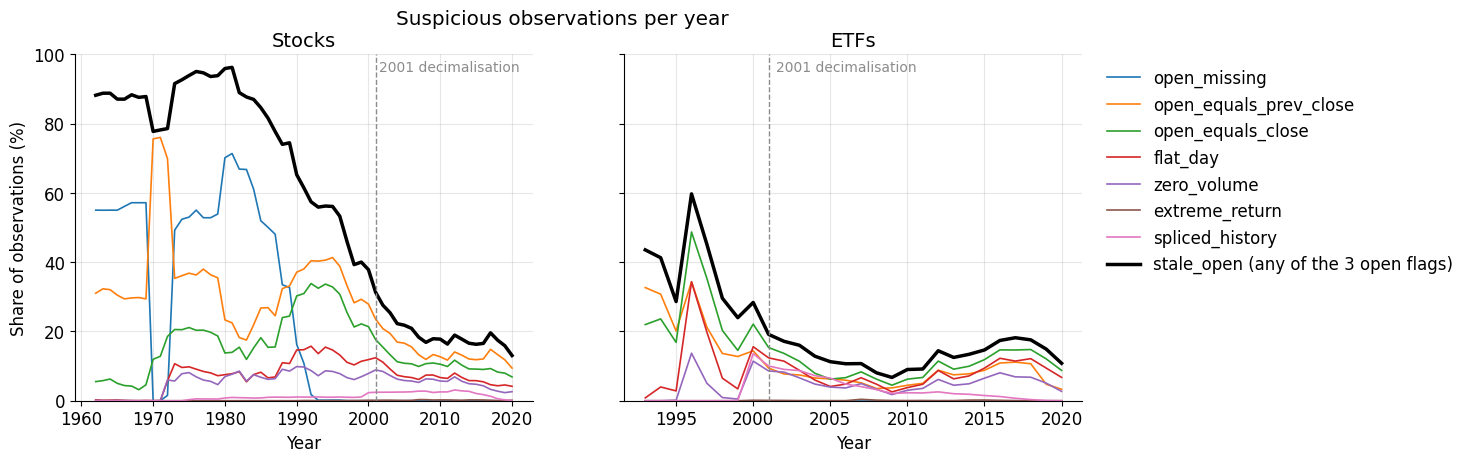

In [11]:
prices = flag_suspicious(add_dollar_volume(add_returns(prices)))
share = suspicious_share_by_year(prices)
fig = plot_suspicious_share(share)

Share of flagged stock observations in selected years (the `spliced_history` column is the one cited below):

In [12]:
(100 * share.loc["stock"].loc[[1980, 1990, 1997, 2000, 2001, 2005, 2019]]).round(1)

,open_missing,open_equals_prev_close,open_equals_close,flat_day,zero_volume,extreme_return,spliced_history,stale_open
year,,,,,,,,
1980,70.1,23.3,13.8,7.5,7.0,0.0,0.8,95.9
1990,16.2,37.1,30.2,14.6,9.9,0.0,1.1,65.2
1997,0.0,33.3,25.5,11.1,6.7,0.0,1.0,46.0
2000,0.0,27.9,21.4,11.9,7.9,0.1,2.3,37.8
2001,0.0,23.5,17.6,12.4,8.9,0.1,2.4,31.3
2005,0.0,16.6,10.8,6.9,5.8,0.1,2.5,21.8
2019,0.0,11.8,8.0,4.5,2.3,0.0,0.3,15.9


Missing opens around the start of the study period (counts, not shares: 88 rows in 1997 round to 0.0 %):

In [13]:
flag_count_by_year(prices, "open_missing").loc[1995:1999]

year
1995    647
1996    709
1997     88
1998      0
1999      0
Name: open_missing, dtype: int64

Tickers whose history is cut by `spliced_history`, with three hand-checked examples:

In [14]:
print(f"{prices.loc[prices.spliced_history, 'ticker'].nunique()} tickers, {prices.spliced_history.sum():,} rows")
splice_examples(prices, ["FTAI", "BILL", "NVR"])

324 tickers, 503,694 rows


,first date,jump date,close before,close after,flagged rows
FTAI,1996-01-03,2015-05-14,759.90,17.00,4845
BILL,2014-07-21,2019-12-12,2.88,35.50,146
NVR,1985-07-22,1993-10-01,0.38,10.25,2073


**Takeaway:** Before 1997, open prices are largely unusable: in 1980, 70.1 % of stock opens are missing and 95.9 % are stale. Missing opens fall to 88 rows in 1997 and to 0 from 1998. Stale opens remain frequent: they fall from 37.8 % of stock observations in 2000 to 21.8 % in 2005, a decline that is consistent with the 2001 decimalisation of US prices, and still reach 15.9 % in 2019. ETFs show the same pattern at a lower level (28.4 % stale in 2000, 11.3 % in 2005, 14.9 % in 2019). Extreme returns are rare (at most 0.2 % per year). `spliced_history` flags 323 tickers (up to 2.5 % of stock observations per year; 13.6 % of ETF observations in 2000). FTAI and BILL are splices (another series glued before the listing); NVR in 1993 may be a real recapitalisation: the rule can drop a true history.

Stale opens are not all recording errors. Share of stale opens (%) by quintile of the previous day's dollar volume (Q1 = least traded) and by previous close, from 1998:

In [15]:
stale_share_by_liquidity(prices, start_year=STUDY_START_YEAR)

,Q1,Q2,Q3,Q4,Q5,price < $5,price >= $5
asset_type,,,,,,,
etf,40.8,8.7,6.7,6.3,5.0,68.1,13.5
stock,49.4,21.1,15.3,10.4,7.2,38.6,17.5


**Takeaway:** Stale opens are concentrated among illiquid names: 49.4 % of stock days in Q1, against 7.2 % in Q5; 38.6 % when the previous close is below \$5, against 17.5 % above. Even the most traded quintile still has 7.2 % stale opens, so some equalities are genuine prices. Removing them selects observations by their return. Whether that choice changes the night–day gap is tested in II.3.

> **Decision.** The study period starts in **1998**, the first year with 0 missing opens (88 remain in 1997). The main analysis uses a **liquidity filter**: it drops a row when the previous close is below \$5 or the previous day's dollar volume is in the bottom 20 % of its year, and also drops missing opens, extreme returns and spliced histories. Previous-day values are known before the night starts. This is the usual finance screen; it does not select on the return of the day itself. Section II.3 compares three versions: this liquidity filter, a stale-open filter, and a light filter (missing opens, extreme returns and spliced histories only). Whether the choice affects the gap is tested there.

In [16]:
filter_summary(prices, start_year=STUDY_START_YEAR)

,rows kept,% of all rows,% of study period
liquidity,17268485,61.4,74.1
stale,18639526,66.3,80.0
light,22826350,81.1,98.0


In [17]:
filtered = apply_quality_filter(prices, start_year=STUDY_START_YEAR, drop_flags=FILTERS["liquidity"])
print(f"Main (liquidity) filter: kept {len(filtered) / len(prices):.1%} of all observations")

Main (liquidity) filter: kept 61.4% of all observations


## I.7 Descriptive statistics

Missing values per column in the cleaned table (`prices`, all years):

In [18]:
missing_values(prices, ["open", "close", "open_adj", "high_adj", "low_adj", "close_adj", "volume", "r_night", "r_day"])

,missing,share (%)
open,1176088,4.18
close,0,0.00
open_adj,1176088,4.18
high_adj,153,0.00
low_adj,153,0.00
close_adj,0,0.00
volume,0,0.00
r_night,1210137,4.30
r_day,1176088,4.18


`open` is missing where the raw open was 0 (I.6), and returns are missing when the open is missing or the previous trading day is absent. `high_adj` and `low_adj` are missing where `High < Low`.

The return statistics below use the main analysis sample (`filtered`: 1998 onwards, liquidity filter). Distribution of overnight and intraday returns:

In [19]:
return_stats(filtered)

n  mean (%)  median (%)  std (%)  p1 (%)  p99 (%)  \
asset_type return                                                             
stock      night   14182284     0.039       0.000    1.515  -4.078    4.286   
           day     14186581    -0.003       0.000    2.562  -7.317    7.568   
etf        night    3079774     0.039       0.039    1.205  -3.475    3.384   
           day      3081904    -0.027       0.000    1.373  -4.153    3.921   

                   skewness  excess kurtosis  
asset_type return                             
stock      night      0.008           95.514  
           day        0.452           21.269  
etf        night     -0.156           70.693  
           day       -0.258           39.686

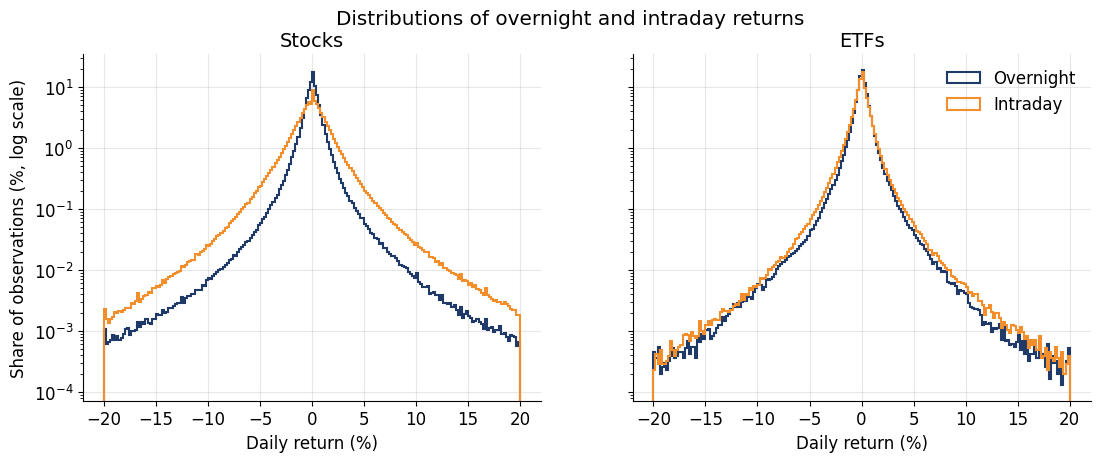

In [20]:
fig = plot_return_distributions(filtered)

**Takeaway:** Returns are strongly heavy-tailed: excess kurtosis ranges from 21 to 96 (0 for a normal distribution). The **mean** overnight return of stocks is 0.039 % **per day**, against −0.003 % intraday; for ETFs the means are 0.039 % overnight and −0.027 % intraday. Medians sit at 0. The trading session is more volatile than the night (stock standard deviation 2.56 % vs 1.52 %) even though it lasts about 6 h 30 against 17 h 30, so per hour the gap is larger still. These pooled figures give more weight to tickers with long histories; Part II tests the gap properly, with medians and robust tests alongside means because of the heavy tails.

Correlation between the overnight and the intraday return of the same day, on `filtered`. Pearson measures a linear relation and is sensitive to extreme values; Spearman uses ranks, so it is robust to heavy tails:

In [21]:
night_day_correlation(filtered)

,pearson,spearman
asset_type,,
stock,-0.080,-0.071
etf,-0.023,-0.014


**Takeaway:** Overnight and intraday returns are negatively correlated, more for stocks (Pearson −0.08, Spearman −0.07) than for ETFs (−0.02, −0.01): part of the overnight move tends to be reversed during the day. A noisy opening price also creates this mechanically (an open that is too high makes the night look better and the day worse). The correlation is weaker here than on unfiltered data, which is consistent with that mechanical channel.

Distribution of daily **dollar** volume (`prices`, all years: this describes the raw cleaned table, not `filtered`):

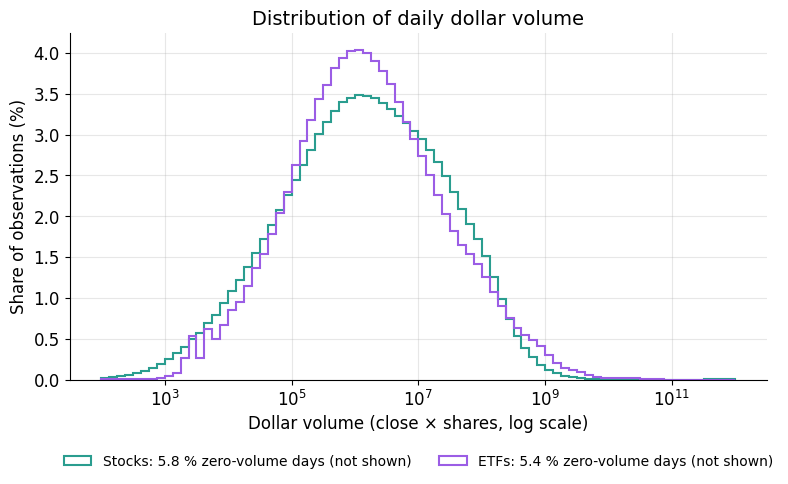

In [22]:
fig = plot_volume_distribution(prices)

In [23]:
volume_summary(prices)

,zero-volume days (%),p1 ($),median ($),p99 ($)
asset_type,,,,
stock,5.8,1250,1453500,497385426
etf,5.4,2852,1392248,1108722747


In [24]:
stale_among_zero_volume(prices)

zero-volume days           1610344.0
of which stale open (%)         92.7
dtype: float64

**Takeaway:** On traded days, stock dollar volume ranges from \$1,250 (1st percentile) to \$497 million (99th), about five orders of magnitude, hence the log scale. In dollars, the median ETF (\$1.39 million) is close to the median stock (\$1.45 million): the gap seen in share counts is mostly a difference of price per share. 5.8 % of stock days and 5.4 % of ETF days have zero volume; 92.7 % of those zero-volume days also have a stale open.

# Part II — The Crime (preliminary results)

These results establish that the anomaly is present in our data, which makes the project feasible. They will be extended and tested further in P3.

Invested only overnight, \$1 in SPY grows several-fold over 1998–2020; invested only during the trading day, it loses money (II.1). That is strange: the session is when almost all trading, price discovery and news reaction happen, so both halves should earn something if returns reward risk or information.

This chapter is **descriptive** (lecture 06): it establishes the fact before asking why. Four questions: Does the crime exist (SPY)? Is it universal? Does it survive the quality filters of Part I? Is the gap distinguishable from zero?

## II.1 Does the crime exist? (SPY)

The value of \$1 invested only in one half of the day, and the convention used to annualise:

$$V_T = \prod_{t \le T} (1 + r_t), \qquad \text{annualised mean} = 252 \times \text{mean daily return}$$

252 is the usual number of US trading days in a year. Buy-and-hold compounds both halves each day: $(1+r^{\text{night}}_t)(1+r^{\text{day}}_t)$.

Log returns split the close-to-close return exactly (lecture 05, log outcomes for heavy tails):

$$\underbrace{\log\frac{\text{close\_adj}_t}{\text{close\_adj}_{t-1}}}_{\text{total}} = \underbrace{\log(1+r^{\text{night}}_t)}_{\text{night}} + \underbrace{\log(1+r^{\text{day}}_t)}_{\text{day}}$$

Their sums tell us what share of the total return comes from the night. SPY, the largest US equity ETF, from the start of the study period:

,first date,last date,days,value of $1,annualised mean (%),share of log return (%)
overnight,1998-01-02,2020-04-01,5598,4.74,7.64,116.61
intraday,1998-01-02,2020-04-01,5598,0.80,0.29,-16.61
buy-and-hold,1998-01-02,2020-04-01,5598,3.80,7.98,100.00


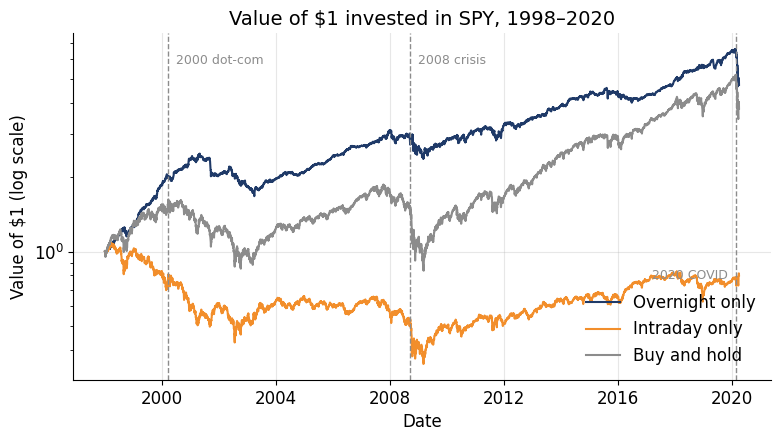

In [25]:
wealth = ticker_wealth(filtered, "SPY")
fig = plot_wealth(wealth, f"Value of $1 invested in SPY, {STUDY_START_YEAR}–2020")
crime_headline(filtered, "SPY")

**Takeaway:** \$1 invested in SPY from 2 January 1998 to 1 April 2020 became \$4.74 overnight only, \$0.80 during the trading day only, and \$3.80 buy-and-hold. The night's annualised mean return is 7.64 %, the day's 0.29 %. Because the day lost money, the night accounts for 116.6 % of the total log return. The trading session, where almost everything happens, earned close to nothing; the closed market earned the gain. II.2 asks whether this is only SPY.

## II.2 Is it universal?

A portfolio return on day $t$ is the cross-section of the tickers available that day:

- equal-weighted: $r^{\text{EW}}_t = \frac{1}{N_t}\sum_i r_{i,t}$;
- dollar-volume-weighted: $r^{\text{DV}}_t = \sum_i w_{i,t}\, r_{i,t}$, with $w_{i,t}$ proportional to the **mean** of `close × volume` over the previous **20** trading days.

The 20-day window is known before the night starts. A one-day volume spike would overweight names that just attracted attention — the crowd hypothesis of Part V — so a month of volume is a more stable liquidity weight. This is still not a market-cap weighting: market capitalisation is not in the dataset.

Before aggregating, we drop ETFs whose US "night" is not mysterious, or whose returns are mechanical. A name is flagged if `security_name` contains one of these keywords (case-insensitive):

- foreign markets: `japan`, `europe`, `eurozone`, `emerging`, `china`, `chinese`, `india`, `brazil`, `korea`, `mexico`, `australia`, `hong kong`, `taiwan`, `russia`, `latin`, `eafe`, `frontier`, `international`, `germany`, `united kingdom`, `britain`, `asia`, `pacific`, `africa`;
- leveraged / inverse: `ultrashort`, `ultrapro`, `ultra `, `inverse`, `2x`, `3x`, `bear 1x`/`2x`/`3x`, `bull 2x`/`3x`, `leveraged`, `proshares short`.

These ETFs can be put back as a sanity check; they are not in the main figures.

In [26]:
meta = tag_special_etfs(meta)
etf_exclusion_counts(meta)

,ETFs
all ETFs,2165
foreign,418
leveraged / inverse,191
both,31
kept in the main analysis,1587


In [27]:
study = exclude_special_etfs(filtered, meta)
print(f"Study sample: {len(study):,} rows after ETF exclusions")
ports = study_portfolios(study)
portfolio_headlines(ports)

Study sample: 16,456,074 rows after ETF exclusions


first date   last date  days  \
portfolio              strategy                                     
Stocks, equal-weighted overnight     1998-01-02  2020-04-01  5598   
                       intraday      1998-01-02  2020-04-01  5598   
                       buy-and-hold  1998-01-02  2020-04-01  5598   
Stocks, dollar-volume  overnight     1998-02-02  2020-04-01  5578   
                       intraday      1998-02-02  2020-04-01  5578   
                       buy-and-hold  1998-02-02  2020-04-01  5578   
ETFs, equal-weighted   overnight     1998-01-02  2020-04-01  5598   
                       intraday      1998-01-02  2020-04-01  5598   
                       buy-and-hold  1998-01-02  2020-04-01  5598   
ETFs, dollar-volume    overnight     1998-02-02  2020-04-01  5578   
                       intraday      1998-02-02  2020-04-01  5578   
                       buy-and-hold  1998-02-02  2020-04-01  5578   

                                     value of $1  annualised mean (%)  \
portfolio              strategy                                         
Stocks, equal-weighted overnight            9.10                10.39   
                       intraday             1.04                 1.38   
                       buy-and-hold         9.47                11.99   
Stocks, dollar-volume  overnight           23.65                15.21   
                       intraday             0.24                -4.43   
                       buy-and-hold         5.70                10.82   
ETFs, equal-weighted   overnight           21.63                14.40   
                       intraday             0.16                -7.41   
                       buy-and-hold         3.49                 7.09   
ETFs, dollar-volume    overnight            8.90                10.61   
                       intraday             0.29                -3.79   
                       buy-and-hold         2.57                 6.83   

                                     share of log return (%)  
portfolio              strategy                               
Stocks, equal-weighted overnight                       98.22  
                       intraday                         1.78  
                       buy-and-hold                   100.00  
Stocks, dollar-volume  overnight                      181.70  
                       intraday                       -81.70  
                       buy-and-hold                   100.00  
ETFs, equal-weighted   overnight                      246.16  
                       intraday                      -146.16  
                       buy-and-hold                   100.00  
ETFs, dollar-volume    overnight                      231.25  
                       intraday                      -131.25  
                       buy-and-hold                   100.00

Equal-weighted and dollar-volume-weighted paths for stocks, then for the remaining ETFs:

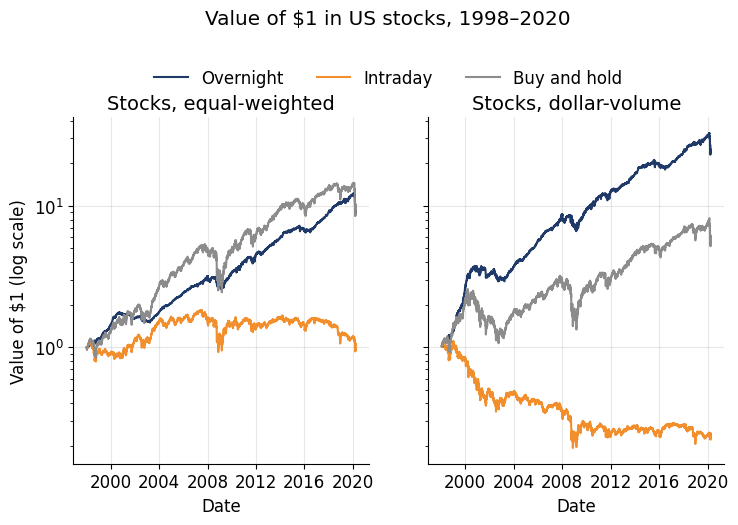

In [28]:
fig = plot_wealth_grid(
    portfolio_paths(ports, ["Stocks, equal-weighted", "Stocks, dollar-volume"]),
    f"Value of $1 in US stocks, {STUDY_START_YEAR}–2020",
)

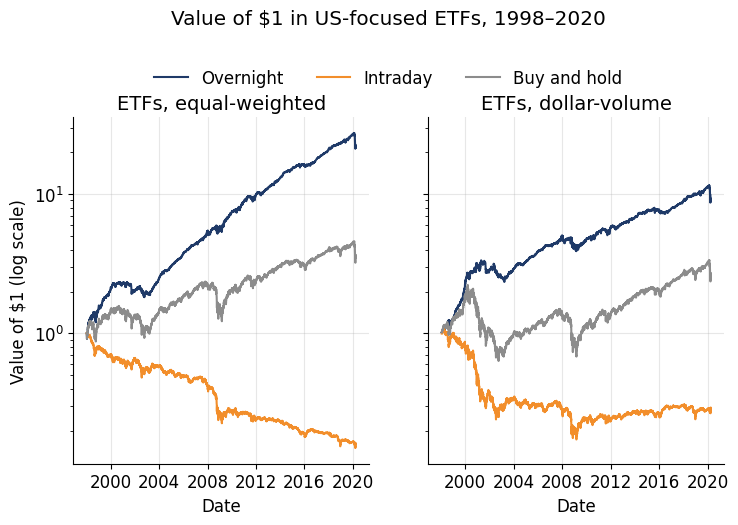

In [29]:
fig = plot_wealth_grid(
    portfolio_paths(ports, ["ETFs, equal-weighted", "ETFs, dollar-volume"]),
    f"Value of $1 in US-focused ETFs, {STUDY_START_YEAR}–2020",
)

**Takeaway:** The crime is not only SPY. \$1 in an equal-weighted stock portfolio became \$9.10 overnight and \$1.04 during the day; dollar-volume-weighted stocks became \$23.65 overnight and \$0.24 during the day. US-focused ETFs show the same split (equal-weighted: \$21.63 vs \$0.16). The trading day earns little or loses money; the night earns the gain. Dollar-volume weights, which load on liquid names, make the split larger, not smaller.

For each ticker with at least 252 paired returns, the annualised gap `mean(r_night) − mean(r_day)`:

,tickers,night > day (%),median gap (%)
asset_type,,,
stock,4885,58.6,6.2
etf,1112,84.8,15.4


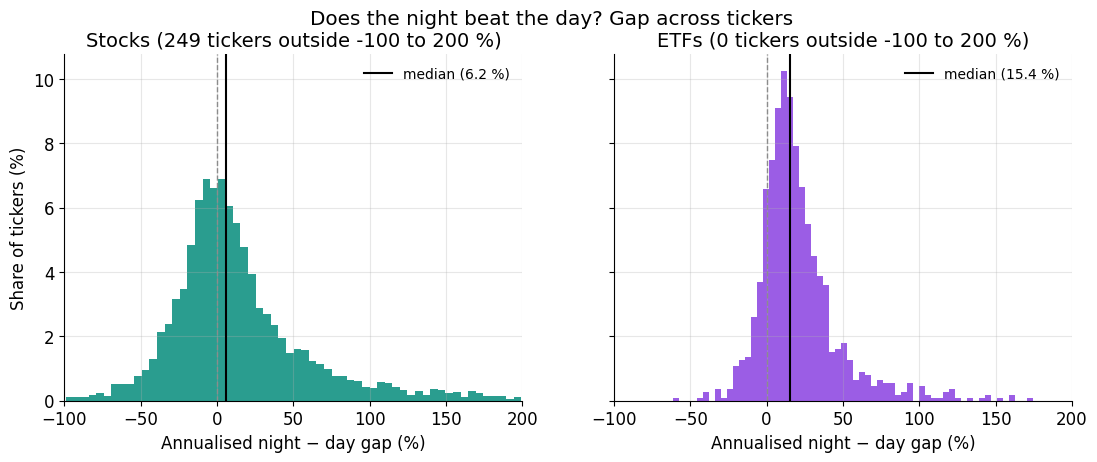

In [30]:
gaps = night_day_gap_by_ticker(study)
fig = plot_gap_histogram(gaps)
gap_share_above_zero(gaps)

**Takeaway:** The night earns more than the day for 58.6 % of stocks and 84.8 % of the remaining ETFs. The median annualised gap is 6.2 % for stocks and 15.4 % for ETFs. The pattern is common, not a handful of famous tickers. It is not universal among stocks: about two in five have the opposite sign.

Where and when: annualised gap by year, for stocks, ETFs, and quintiles of the 20-day lagged dollar volume (Q1 = least traded). 2020 is omitted (data end on 1 April):

,Stocks,ETFs,Q1,Q2,Q3,Q4,Q5
year,,,,,,,
2000,17.2,20.4,-14.2,-6.5,13.7,37.1,50.3
2008,11.4,49.7,40.6,23.0,4.7,-0.7,11.2
2009,-0.5,21.7,29.4,7.0,-0.6,-14.0,-10.2
2019,9.6,11.0,21.1,11.7,6.1,4.3,3.6


,Stocks,ETFs,Q1,Q2,Q3,Q4,Q5
mean,10.2,22.7,10.0,11.1,8.9,9.9,13.6


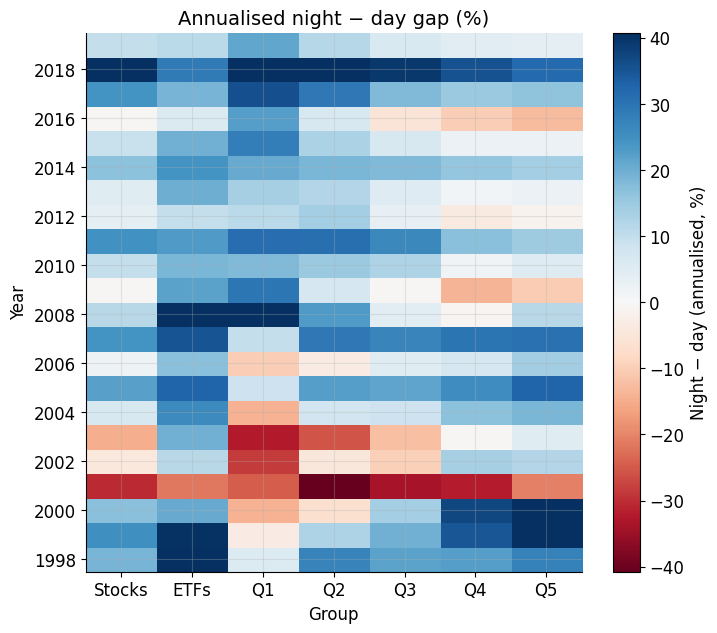

In [31]:
heat = gap_heatmap_table(study)
fig = plot_gap_heatmap(heat)
display(heat.loc[[2000, 2008, 2009, 2019]])
heat.mean().to_frame("mean").T.round(1)

**Takeaway:** The gap is positive in most years and groups (column means shown under the figure: 10.2 % for stocks, 22.7 % for ETFs). It is not confined to illiquid names: in 2019 it is 3.6 % even in Q5. Exceptions exist: stocks in 2009 (−0.5 %), and some quintiles in 2000 and 2008 change sign. The 2008 crisis is a large *positive* gap for ETFs (49.7 %): the night earned while the session sold off.

## II.3 Does it survive data cleaning?

Section I.6 announced three filters. The next table and figure apply each of them to SPY and to equal-weighted stocks (no ETF exclusion here, so the comparison isolates the filter):

,SPY night,SPY day,SPY gap,EW stocks night,EW stocks day,EW stocks gap
liquidity,7.64,0.29,7.35,10.39,1.38,9.00
stale,7.48,-0.27,7.75,13.48,9.49,4.00
light,7.64,0.29,7.35,9.05,7.78,1.27


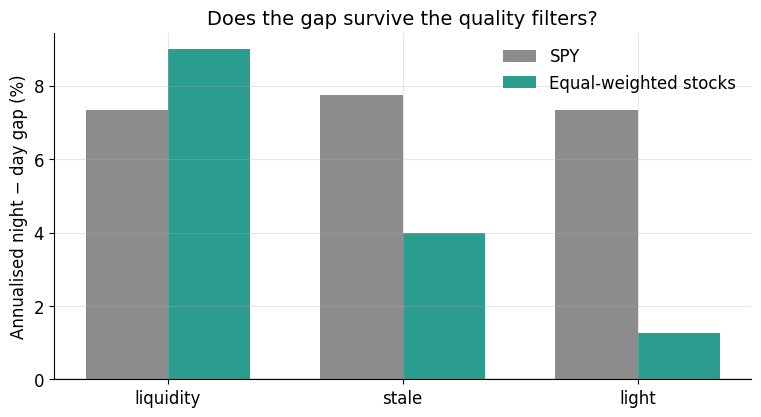

In [32]:
cmp = filter_comparison(prices, start_year=STUDY_START_YEAR, filters=FILTERS)
fig = plot_filter_comparison(cmp)
cmp

**Takeaway:** On SPY the gap is almost the same under every filter (7.35 % liquidity and light, 7.75 % stale). On equal-weighted stocks it shrinks when we keep illiquid names: 9.01 % with the liquidity filter, 4.00 % with the stale-open filter, 1.27 % with the light filter. On SPY the crime is not created by how stale opens are treated; in the cross-section it is concentrated among liquid names. With the light filter, the equal-weighted stock *day* return is 7.78 % a year, against 1.38 % under the liquidity filter: illiquid names earn a lot during the session, which is consistent with bid–ask bounce (see the limits below). Whether the liquid sample is the economically relevant one is a choice; the three numbers are the robustness check.

## II.4 Is it statistically significant?

Comparing two separately computed means ignores that night and day of the same date are paired. Lecture 05 stacks them and estimates one coefficient:

$$r_{t,s} = \alpha + \beta \cdot \mathbb{1}[s=\text{night}] + \varepsilon_{t,s}$$

$\beta$ is the mean night − day difference. Standard errors are **clustered by date**, so the two halves of the same day are not treated as independent.

Errors are also autocorrelated across days. A **block bootstrap** of $d_t = r^{\text{night}}_t - r^{\text{day}}_t$ (blocks of 21 consecutive trading days, 1,000 resamples) gives a second 95 % interval. Each test below is one portfolio over the full study period. The table gives the portfolio name and the dates.


**SPY, 1998–2020.** Night-indicator regression.


In [33]:
spy = study.loc[study["ticker"] == "SPY", ["date", "r_night", "r_day"]].dropna()
label_sample(night_indicator_regression(spy), "SPY", spy)


,portfolio,first date,last date,beta daily (%),beta annualised (%),SE daily (%),CI 95% low,CI 95% high,p-value,n days
0,SPY,1998-01-02,2020-04-01,0.0292,7.351,0.0163,-0.6877,15.3898,0.0731,5598


**SPY, 1998–2020.** Block bootstrap of the daily night − day gap.


In [34]:
label_sample(block_bootstrap_ci(spy["r_night"] - spy["r_day"]), "SPY", spy)


,portfolio,first date,last date,block,resamples,mean daily (%),mean annualised (%),CI 95% low,CI 95% high
0,SPY,1998-01-02,2020-04-01,21,1000,0.03,7.35,0.3,15.69


**Equal-weighted stocks, 1998–2020.** Night-indicator regression.


In [35]:
ew = ports["Stocks, equal-weighted"].dropna(subset=["r_night", "r_day"])
label_sample(night_indicator_regression(ew), "Equal-weighted stocks", ew)


,portfolio,first date,last date,beta daily (%),beta annualised (%),SE daily (%),CI 95% low,CI 95% high,p-value,n days
0,Equal-weighted stocks,1998-01-02,2020-04-01,0.0357,9.005,0.0142,1.9975,16.0125,0.0118,5598


**Equal-weighted stocks, 1998–2020.** Block bootstrap of the daily night − day gap.


In [36]:
label_sample(block_bootstrap_ci(ew["r_night"] - ew["r_day"]), "Equal-weighted stocks", ew)


,portfolio,first date,last date,block,resamples,mean daily (%),mean annualised (%),CI 95% low,CI 95% high
0,Equal-weighted stocks,1998-01-02,2020-04-01,21,1000,0.04,9.0,2.95,16.13


**Equal-weighted ETFs, 1998–2020.** Night-indicator regression.


In [37]:
etf = ports["ETFs, equal-weighted"].dropna(subset=["r_night", "r_day"])
label_sample(night_indicator_regression(etf), "Equal-weighted ETFs", etf)


,portfolio,first date,last date,beta daily (%),beta annualised (%),SE daily (%),CI 95% low,CI 95% high,p-value,n days
0,Equal-weighted ETFs,1998-01-02,2020-04-01,0.0865,21.8054,0.0133,15.2299,28.3809,0.0,5598


**Equal-weighted ETFs, 1998–2020.** Block bootstrap of the daily night − day gap.


In [38]:
label_sample(block_bootstrap_ci(etf["r_night"] - etf["r_day"]), "Equal-weighted ETFs", etf)


,portfolio,first date,last date,block,resamples,mean daily (%),mean annualised (%),CI 95% low,CI 95% high
0,Equal-weighted ETFs,1998-01-02,2020-04-01,21,1000,0.09,21.81,17.26,27.97


**Takeaway:** Over 1998–2020, the SPY result is **borderline and method-dependent**: clustered standard errors give 7.35 % with a 95 % CI of [−0.69, 15.39] (p = 0.073, includes 0); the block bootstrap gives [0.30, 15.69] (excludes 0). The same tests support a gap for equal-weighted stocks (9.01 %, p = 0.012, bootstrap [2.95, 16.13]) and for equal-weighted ETFs (21.81 %, p = 0.000, bootstrap [17.26, 27.97]).


## Conclusion

- **The crime appears on SPY** (1998–2020): \$1 became \$4.74 overnight and \$0.80 during the day. The night's share of the log return is 116.6 % because the day lost money.
- **It is typical, not unique**: Equal-weighted stocks, dollar-volume-weighted stocks and US-focused ETFs all earn almost everything overnight. The night beats the day for 58.6 % of stocks and 84.8 % of those ETFs.
- **On SPY it does not depend on how stale opens are treated; in the cross-section it is concentrated among liquid names.** The same regression supports a gap for equal-weighted stocks (9.01 %, p = 0.012) and for equal-weighted ETFs (21.81 %, p = 0.000).

**Limits of this chapter:** Survivorship bias (I.3) still applies. Opening prices remain noisy for illiquid names; we showed three filters rather than claiming one is true. There is no market cap, only liquidity weights. Daily equal-weighted portfolios of less liquid names are inflated by bid–ask bounce; the liquidity filter reduces that bias but does not remove it. Foreign and leveraged ETFs were dropped by a keyword list that can miss or over-exclude.

## Next steps for P3

1. Evolution over time:

   Track the night–day gap in a rolling window for SPY, equal-weighted stocks and ETFs, and see whether the gap stays put or moves across the sample.

2. Return and volatility per hour:

   The night lasts longer than the trading session. Compare return and volatility per hour, so a larger overnight gain is not just a longer clock.

3. COVID, February–April 2020:

   Zoom in on the crash and the rebound, and separate what happened overnight from what happened during the day.

4. Weighting and ETF robustness:

   The portfolios already use a 20-day dollar-volume window. Still to check: volatility and commodity ETFs, which can pull an equal-weighted ETF book even after the foreign and leveraged names are dropped.

5. Transaction costs:

   An overnight-only strategy trades twice a day. The verdict needs a cost check before it says the night is worth holding.

6. One filter for the whole team:

   Every later chapter should use the same sample. The group has to confirm the liquidity filter as that common default.

**Who is guilty?** Part III asks whether longer nights pay more (risk). Part IV asks whether news lands after the close. Part V asks whether a crowd of attention produces an overnight gain and an intraday hangover. Part VI uses mistaken tickers as a natural experiment. The verdict is for P3.


# Part III: The Risk Suspect (preliminary results)

Part II established the crime. We now question the first suspect: **risk**. Holding a security overnight exposes investors to news they cannot trade on until the next open. If that risk is compensated, and it grows with the length of the closure, longer closures should earn more. Two hypotheses make different predictions:

- **Per hour (calendar time):** the overnight return accrues with the hours elapsed. A weekend of about 66 hours should earn about 3.7 times a weekday night of 17.5 hours.
- **Per night:** the overnight return is a fixed amount per closure, whatever its length.

**Roadmap.** III.1 measures the length of each night. III.2 compares mean returns across closure types. III.3 regresses returns on hours to test both hypotheses. III.4 checks whether the result depends on our choices, on a few exceptional closures or on the 2008 break found in Part II.

We use the four portfolios from Part II (stocks and ETFs, each equal-weighted and dollar-volume-weighted) under the common **liquidity** filter and the same ETF exclusions, from 2 January 1998 to **1 April 2020**. This tests one prediction of a risk explanation; risk itself is not measured here.

## III.1 How long is a night?

A night runs from the **previous market session's close** to the current open. We measure elapsed hours using the historical [NYSE schedule](https://pandas-market-calendars.readthedocs.io/en/latest/usage.html), including holidays and special opening and closing times. UTC timestamps account for US clock changes.

Consecutive dates are weekday nights; Friday–Monday is a weekend; Thursday–Monday or Friday–Tuesday is a long weekend. Midweek holidays are separate. **Exceptional closures** include full-day shutdowns outside the regular holiday schedule, such as those following September 2001 or Hurricane Sandy. Early closes and clock changes remain calendar flags.

The table describes these intervals. Returns remain those calculated before filtering in Part I.

In [39]:
from src.features.calendar import study_night_calendar
from src.analysis.risk import (
    risk_samples, risk_type_analysis, duration_tests_by_period, duration_predictions,
    duration_robustness, risk_filter_comparison, proportionality_tests,
)
from src.visualization.plots import plot_risk_by_night_type, plot_duration_predictions, plot_duration_slopes
from src.visualization.risk_tables import (
    calendar_table, closure_counts_table, contrast_table, proportionality_table,
    robustness_table, exceptional_closure_table,
)

night_calendar = study_night_calendar(prices, start_year=STUDY_START_YEAR)
calendar_table(night_calendar)

,nights,mean hours
night_type,,
Weekday,4383,17.50
Midweek holiday,53,42.58
Weekend,1013,65.57
Long weekend,144,89.62
Exceptional closure,5,103.91


**Takeaway:** A weekend lasts about 66 hours, 3.7 times a 17.5-hour weekday night, so the two hypotheses predict very different weekend returns. Early closes and clock changes also shift durations: a fixed number of hours for every Monday would miss these differences. The five exceptional closures are shutdowns caused by an event; III.4 examines them separately.

## III.2 Do longer closures earn more?

We first compare mean overnight returns across closure types, without imposing any functional form. The top row shows stocks and the bottom row ETFs; the left column uses equal weights and the right column uses weights based on average dollar volume over the previous 20 observations.

Each point shows a category's mean return at its mean closure duration, in basis points per night (1 bp = 0.01 %). The bars are 95 % confidence intervals from 1,000 block-bootstrap resamples, using blocks of 21 consecutive market sessions. Each portfolio contributes one return per observed night: 5,598 for equal-weighted portfolios and 5,578 for dollar-volume-weighted ones, which need an initial 20-observation window. The table below the figure gives the number of nights per type and weighting. Counts are identical for stocks and ETFs.

We read the duration pattern within each portfolio. Differences between stocks and ETFs also reflect their composition and do not isolate an ETF effect. The five exceptional closures are left out of the figure.

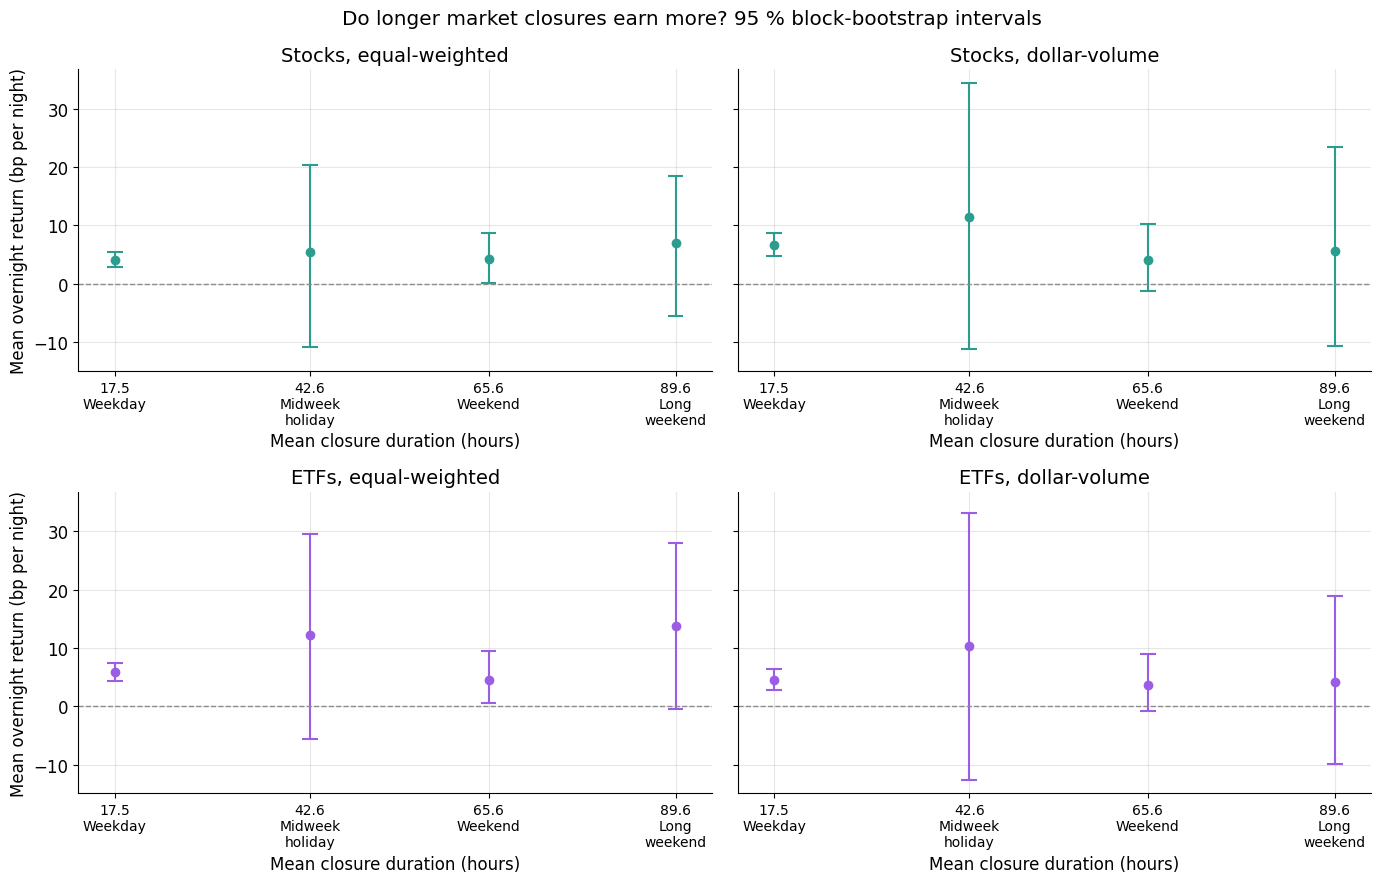

In [40]:
risk = risk_samples(study, night_calendar)
risk_summaries, risk_contrasts = risk_type_analysis(risk)
fig = plot_risk_by_night_type(risk_summaries)

In [41]:
closure_counts_table(risk_summaries)

,Equal-weighted,Dollar-volume-weighted
night_type,,
Weekday,4383,4368
Weekend,1013,1010
Long weekend,144,143
Midweek holiday,53,52
Exceptional closure,5,5


**Takeaway:** Mean returns do not rise steadily with duration in any of the four portfolios. Midweek holidays have higher sample means than weekday nights and normal weekends in all four portfolios, and the highest means in both dollar-volume-weighted portfolios. However, these estimates rely on only **52–53 nights per portfolio** and have wide confidence intervals; their differences from weekday nights remain statistically indistinguishable from zero.

To test these differences, we compare each routine closure type with weekday nights. For each bootstrap draw, we calculate the difference in means and use the resulting distribution to construct a 95 % confidence interval. Differences are in basis points per night, without multiple-comparison correction.

In [42]:
contrast_table(risk_contrasts)

gap (bp)           95% CI
portfolio              contrast                                           
Stocks, equal-weighted Midweek holiday - Weekday     1.42  [-14.61, 16.39]
                       Weekend - Weekday             0.09    [-4.02, 4.99]
                       Long weekend - Weekday        2.91   [-9.50, 14.49]
Stocks, dollar-volume  Midweek holiday - Weekday     4.83  [-17.70, 28.70]
                       Weekend - Weekday            -2.43    [-7.87, 4.38]
                       Long weekend - Weekday       -0.90  [-17.71, 17.06]
ETFs, equal-weighted   Midweek holiday - Weekday     6.44  [-11.63, 23.93]
                       Weekend - Weekday            -1.38    [-5.34, 4.01]
                       Long weekend - Weekday        7.87   [-6.27, 22.23]
ETFs, dollar-volume    Midweek holiday - Weekday     5.83  [-17.46, 29.55]
                       Weekend - Weekday            -0.85    [-5.79, 5.09]
                       Long weekend - Weekday       -0.34  [-14.32, 14.53]

**Takeaway:** Every routine closure contrast includes zero in all four portfolios. The weekend–weekday sample differences are small: **0.09 bp** more for equal-weighted stocks, **2.43 bp** less with dollar-volume weights. Under the per-hour hypothesis, it should earn about 3.7 times as much. Categories, however, mix duration with other calendar features, and some contain few nights. III.3 therefore uses the duration of each night directly.

## III.3 Per hour or per night?

We regress each night's return on its duration:

$$r^{\text{night}}_t = \alpha + \beta h_t + \varepsilon_t$$

Each observation is one market night, with $h_t$ measured in hours. $\beta$ is the change in mean return for one extra hour of closure, in bp per hour. $\alpha$ is the fitted return at zero closure hours, in bp per night; zero hours lies outside the observed durations. The two hypotheses predict:

- **Per hour:** $E[r^{\text{night}}_t] = c\, h_t$, so $\alpha = 0$. This adapts the calendar-time hypothesis of French (1980) to close-to-open returns.
- **Per night:** $\beta = 0$, so the expected return is constant across durations and equals $\alpha$.

We use HAC standard errors with 5 lags to account for changing return variability and dependence between observations up to five nights apart. The regression uses all observed nights, including the five exceptional closures.

The figure plots the **predicted mean overnight return** against duration. The shaded band is a **pointwise 95 % confidence interval for that mean**; individual nightly returns vary much more widely. The dots are the category means of III.2. The figure covers only the range of routine closure durations.

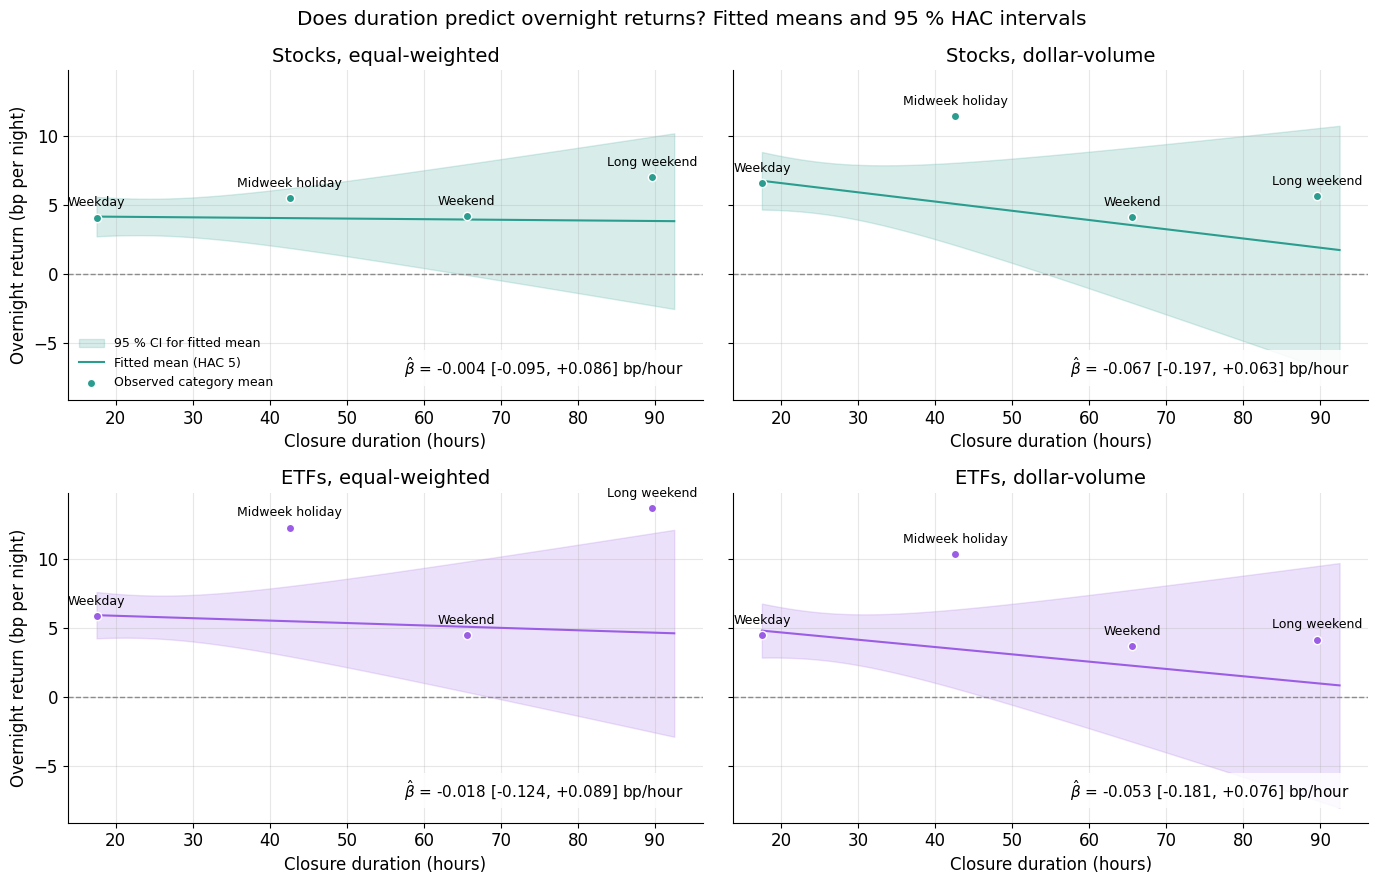

In [43]:
risk_predictions = duration_predictions(risk)
fig = plot_duration_predictions(risk_predictions, risk_summaries)

**Takeaway:** The fitted lines are nearly flat or slope downwards, and all four slope intervals include zero: no statistically significant linear relationship with duration is detected. This is consistent with the per-night hypothesis, but does not establish a constant return. Weekday nights and weekends make up most observations, while exceptional durations can strongly influence the slope. The next table tests strict proportionality to hours.

The table reports $\alpha$ and $\beta$ with their 95 % HAC intervals, using all nights and then excluding the five exceptional closures. The test of $\alpha = 0$ checks strict proportionality to hours within the linear model. The $\beta$ interval shows which duration effects remain compatible with the data.

In [44]:
risk_proportional = proportionality_tests(risk)
proportionality_table(risk_proportional)

alpha, bp/night [95% CI]  \
portfolio              sample                                      
Stocks, equal-weighted All nights              4.25 [1.74, 6.75]   
                       Routine closures        3.83 [1.42, 6.25]   
Stocks, dollar-volume  All nights             7.94 [4.23, 11.64]   
                       Routine closures       7.24 [3.70, 10.78]   
ETFs, equal-weighted   All nights              6.21 [3.26, 9.16]   
                       Routine closures        5.55 [2.77, 8.32]   
ETFs, dollar-volume    All nights              5.71 [2.09, 9.33]   
                       Routine closures        4.70 [1.56, 7.85]   

                                        p (alpha = 0)  beta, bp/hour [95% CI]  
portfolio              sample                                                  
Stocks, equal-weighted All nights             < 0.001  -0.004 [-0.095, 0.086]  
                       Routine closures         0.002   0.013 [-0.072, 0.098]  
Stocks, dollar-volume  All nights             < 0.001  -0.067 [-0.197, 0.063]  
                       Routine closures       < 0.001  -0.038 [-0.158, 0.082]  
ETFs, equal-weighted   All nights             < 0.001  -0.018 [-0.124, 0.089]  
                       Routine closures       < 0.001   0.010 [-0.085, 0.105]  
ETFs, dollar-volume    All nights               0.002  -0.053 [-0.181, 0.076]  
                       Routine closures         0.003  -0.012 [-0.115, 0.091]

**Takeaway:** The intercept ranges from **3.8 to 7.9 bp per night**, and every interval excludes zero ($p \le 0.003$). Within the linear model, this rejects strict proportionality to elapsed hours in all four portfolios, with and without exceptional closures.

All slope intervals include zero. The results remain consistent with a per-night premium, although small duration effects remain possible. This tests one form of the risk explanation: risk itself need not grow with elapsed time.

## III.4 How robust is the result?

We vary one choice at a time in the full-period regression of III.3. The baseline uses **simple returns, the liquidity filter and HAC 5**.

- **HAC 21:** allow dependence over a longer window. This changes the confidence interval while leaving the fitted slope unchanged.
- **Exclude exceptional closures:** check how much the five unusual shutdowns influence the slope.
- **Log portfolio returns:** use $10{,}000 \times \ln(1 + r)$, where $r$ is the daily portfolio return, to check whether the return definition changes the relationship.
- **Alternative quality filters:** check whether the result depends on which securities and observations enter the portfolios, using Part I's stale-open and light filters.

Each entry reports **β [95 % CI]**, in bp per extra hour (log bp for the log-return row). Excluding exceptional closures removes five nights from each portfolio; the other variants keep the same number of nights, although the filters change portfolio composition.

In [45]:
risk_tests = duration_tests_by_period(risk)
risk_checks = duration_robustness(risk)
risk_filters = risk_filter_comparison(prices, night_calendar, start_year=STUDY_START_YEAR, meta=meta)
robustness_table(risk_tests, risk_checks, risk_filters)

,"Stocks, equal-weighted","Stocks, dollar-volume","ETFs, equal-weighted","ETFs, dollar-volume"
specification,,,,
"Main, HAC 5","-0.004 [-0.095, 0.086]","-0.067 [-0.197, 0.063]","-0.018 [-0.124, 0.089]","-0.053 [-0.181, 0.076]"
HAC 21,"-0.004 [-0.093, 0.084]","-0.067 [-0.194, 0.060]","-0.018 [-0.119, 0.084]","-0.053 [-0.178, 0.072]"
Exclude exceptional full-day closures,"0.013 [-0.072, 0.098]","-0.038 [-0.158, 0.082]","0.010 [-0.085, 0.105]","-0.012 [-0.115, 0.091]"
Log returns,"-0.007 [-0.098, 0.084]","-0.070 [-0.202, 0.061]","-0.020 [-0.128, 0.087]","-0.056 [-0.187, 0.075]"
Stale-open filter,"0.011 [-0.080, 0.102]","-0.062 [-0.196, 0.072]","-0.012 [-0.118, 0.094]","-0.052 [-0.181, 0.076]"
Light filter,"-0.003 [-0.084, 0.077]","-0.065 [-0.196, 0.065]","-0.013 [-0.114, 0.088]","-0.053 [-0.181, 0.075]"


**Takeaway:** No specification detects a statistically significant slope: every interval includes zero. Excluding the exceptional closures raises all four slopes and turns both equal-weighted estimates slightly positive; the other choices move the estimates less.

Why do five nights out of about 5,600 matter? Their mean overnight returns, with block-bootstrap intervals:

In [46]:
exceptional_closure_table(risk_summaries)

,n nights,mean (bp),95% CI
portfolio,,,
"Stocks, equal-weighted",5,-85.35,"[-235.85, 29.29]"
"Stocks, dollar-volume",5,-142.00,"[-387.24, 30.73]"
"ETFs, equal-weighted",5,-119.99,"[-357.81, 32.75]"
"ETFs, dollar-volume",5,-179.43,"[-541.47, 34.36]"


**Takeaway:** The five exceptional closures are **high-leverage points**. They lie at the far end of the duration axis (about 104 hours on average), include the reopening after September 2001, and lost **85 to 179 bp per night** on average, against a few bp for routine nights. Excluding them raises the fitted slope in all four portfolios. These returns may reflect the events that caused the closures, so their association with duration is difficult to interpret. With only five nights, their intervals are very wide and include zero. In P3 we will report the slope on routine closures as the main estimate and treat exceptional closures separately.

**Before and after 2008.** Part II found that the SPY gap largely disappears after 2008. We re-estimate the slope separately for 1998–2007 and 2008–2020. Points show 48 times the slope, the model-implied effect of 48 extra closure hours (about the extra length of a weekend), in bp. Bars are pointwise 95 % HAC intervals. Separate estimates do not formally test a change in slope.

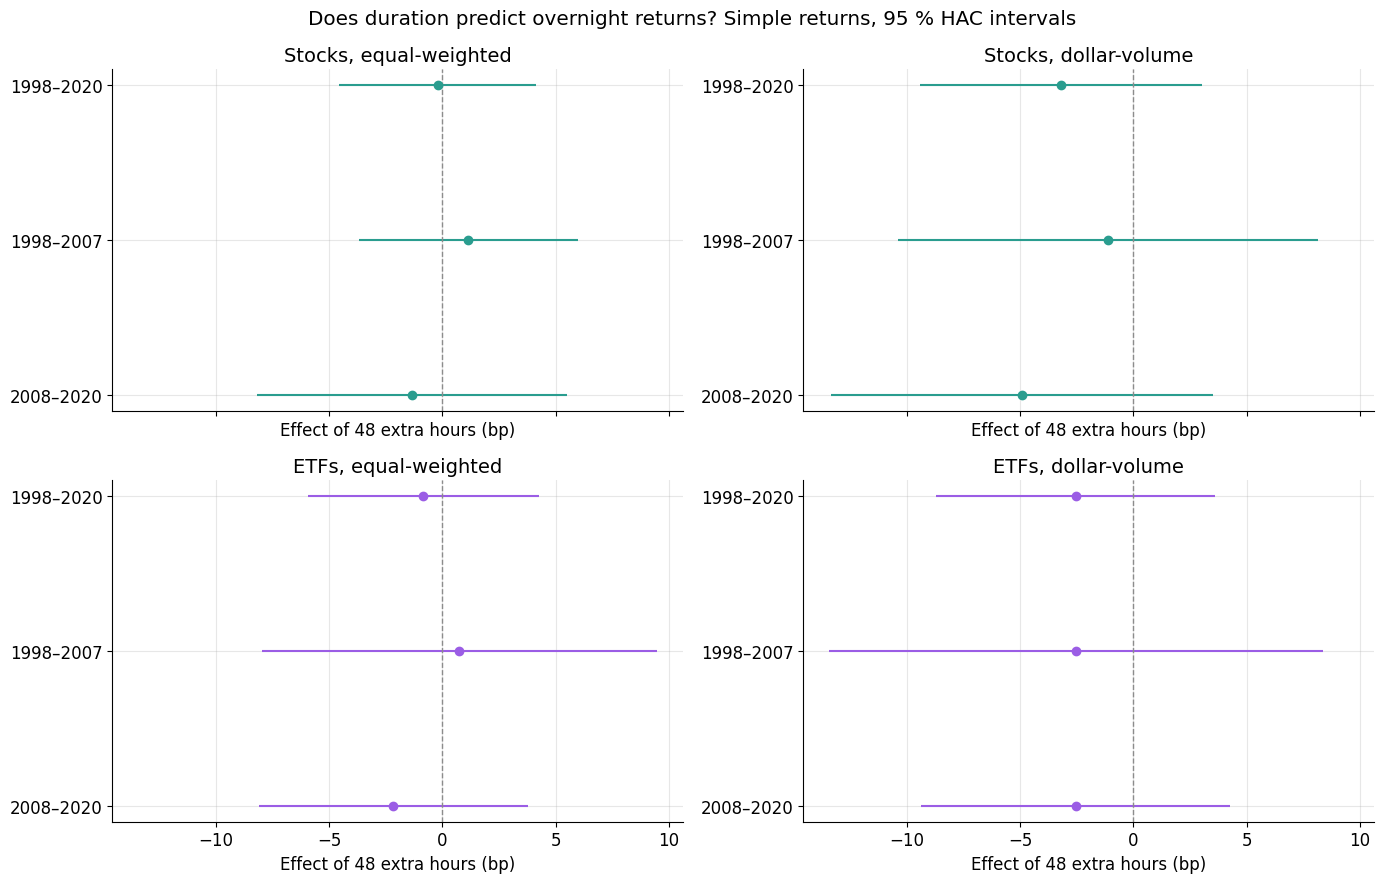

In [47]:
fig = plot_duration_slopes(risk_tests)

**Takeaway:** No statistically significant linear relationship with duration is detected in either period. In all four portfolios, the slope intervals include zero both in 1998–2007 and in 2008–2020. The point estimates imply changes of at most about 5 bp in absolute value for 48 extra closure hours; their intervals allow larger effects. The post-2008 point estimates are all slightly negative, but separate estimates do not test a change in slope. That test, and the question of whether the per-night premium itself fell after 2008, are left for P3.

## Conclusion

**Verdict for P2: no statistically detectable increase in returns with closure duration.**

- **By closure type (III.2):** every routine closure contrast with weekday nights includes zero. Weekend sample means are close to weekday means, although weekends last 3.7 times longer.
- **Per hour or per night (III.3):** the linear model rejects strict proportionality to elapsed hours. All duration-slope intervals include zero, leaving the results consistent with a per-night premium without establishing a constant return.
- **Robustness (III.4):** no statistically significant slope is detected under any return definition, HAC window or quality filter, nor in either period around 2008. Excluding the five exceptional closures raises all four slopes.

Risk has not been cleared, however: risk need not grow with elapsed time, and Part III does not yet measure it. Small per-hour effects also remain possible.

**Limits of this chapter.** Duration varies with weekdays, holidays and news, so an association would not establish causality. It also need not track the amount or type of risk. Survivorship bias and noisy opening prices from Part I still apply; the NYSE schedule is a common reference for the securities in our sample.

## Next steps for P3

1. **Compare volatility across closure types.** Are returns more variable after a weekend or a holiday? If so, do these nights also earn more on average?
2. **Check how much we can conclude.** Estimate the average premium per night with a confidence interval, and check how large a duration effect could still be consistent with our results.
3. **Look at weekdays and holidays.** Check whether the patterns come from the length of the closure or from particular days, such as Mondays and days after holidays.
4. **Take a closer look at 2008.** Test whether average overnight returns and their relationship with duration changed after 2008. Follow the results over rolling three-year windows, and repeat the analysis without 2020 to see how much COVID affects it.
5. **Bring in news and attention.** Use the measures from the other chapters to see whether they help explain the differences between nights.

*References.* French, K. R. (1980). Stock returns and the weekend effect. *Journal of Financial Economics*, 8(1), 55–69. French, K. R. and Roll, R. (1986). Stock return variances: The arrival of information and the reaction of traders. *Journal of Financial Economics*, 17(1), 5–26.

# Part IV: The News Suspect (preliminary results)

Part III found no sign that the overnight return is paid **per hour** of closure, which weakens the risk suspect. The second suspect is **news**. Firms tend to release important information (earnings, mergers, CEO departures) **after the close**, so that investors can digest it before the next session. If new information arrives mostly at night, prices should move mostly at night, and the night might simply collect the reward for news.

**The decisive test.** If news explains the crime, the gap should vanish once we keep only stock-days **without any news**. If quiet nights still beat quiet days, news cannot be the explanation.

**Measuring news: SEC 8-K filings.** A US listed firm must file a form 8-K with the SEC within four business days of any material event. EDGAR records the **acceptance time** of each filing to the second, so we can tell whether it arrived during the night (previous close to open) or during the trading day. Item 2.02 of an 8-K ("Results of Operations") marks earnings announcements.

## IV.1 Linking tickers to SEC filings

`scripts/collect_news.py` (run once, about 20 minutes, cached in `data/edgar/`) links each stock to its SEC identifier (CIK) and downloads the issuer's full 8-K history from the EDGAR submissions API.

Three traps make a naive match wrong:

- The SEC ticker file lists **today's** tickers, not those of April 2020: companies acquired, bankrupt or renamed since then are missing. We recover them by matching the security name against **every name ever registered on EDGAR** (`match = name`).
- A ticker may since have been **reused by another company**. We compare the dataset's security name with the issuer's current and **former** SEC names and reject weak matches (`name_mismatch`).
- **Foreign issuers** (many Chinese and Israeli Nasdaq listings) report events on form 6-K, not 8-K. For them, "no 8-K" does not mean "no news", so they are excluded (`foreign_filer`), as are issuers with no 8-K at all in the period (`no_8k`).

Only `verified` tickers enter the analysis. The table gives the share of stock tickers and of stock rows of the study sample in each category:

In [48]:
from src.data.edgar import load_filings, verify_identity, EDGAR_DIR
from src.analysis.news import (
    session_windows, assign_sessions, filing_time_share_by_year, filing_time_profile, timing_summary,
    coverage_table, name_check_examples, build_news_panel, news_portfolios, news_paths, news_decomposition,
    quiet_gap_tests, quiet_gap_by_period, timing_validation, news_regression, annualised_means, gap_by_issuer_group,
    TIMED_START_YEAR,
)
from src.visualization.news import plot_filing_times, plot_news_wealth, plot_gap_tests
import pandas as pd

stocks = study[study["asset_type"] == "stock"]
identity = verify_identity(pd.read_parquet(EDGAR_DIR / "mapping.parquet"), pd.read_parquet(EDGAR_DIR / "issuers.parquet"))
coverage_table(identity, stocks)

FileNotFoundError: [Errno 2] No such file or directory: '/Users/rania/Projects/Project_ADA_Stock_Markets_TheAnalysts/data/edgar/mapping.parquet'

Rejected matches with the highest name similarity, to check the threshold by eye:

In [ ]:
name_check_examples(identity)

,ticker,security_name,sec_name,former_names,name_score
319,AOS,A.O. Smith Corporation Common Stock,SMITH A O CORP,,0.59
763,BPRN,The Bank of Princeton - Common Stock,"Princeton Bancorp, Inc.",,0.58
4599,RUBI,"The Rubicon Project, Inc. Common Stock",Rubico Inc.,Central Tactical Acquisitions Inc.,0.57
4050,PAM,Pampa Energia S.A. Pampa Energia S.A.,Pampa Energy Inc.,,0.56
433,ATCX,"Atlas Technical Consultants, Inc. - Class A Co...",ATLAS CRITICAL MINERALS Corp,Jupiter Gold Corp,0.56
3816,NTRP,"Neurotrope, Inc. - Common Stock","NextTrip, Inc.","SIGMA ADDITIVE SOLUTIONS, INC.|SIGMA LABS, INC...",0.56
2249,GJT,"Synthetic Fixed-Income Securities, Inc. Synthe...","STRATS(SM) Trust for Allstate Corp Securities,...",,0.56
1493,DIOD,Diodes Incorporated - Common Stock,DIODES INC /DEL/,,0.55


**Who carries the crime?** Before testing the suspect, we check which stocks the test can see. Night − day gap of equal-weighted portfolios by kind of issuer, 1998–2020 (Part II's regression, standard errors clustered by date):

In [ ]:
gap_by_issuer_group(stocks, identity)

,tickers,stock-days,gap annualised (%),CI low,CI high,p-value
"US filer, same ticker today",2650,7951275,3.459,-3.971,10.890,0.362
"US filer, delisted or renamed since 2020",1520,2810375,18.286,10.750,25.823,0.000
foreign filer (6-K / 20-F),700,1414270,20.920,13.379,28.461,0.000
not linked to EDGAR,947,2006364,10.540,5.361,15.720,0.000


**Takeaway:** The crime is not spread evenly. US filers still trading under the same ticker today show a gap of only **3.5 %** a year (p = 0.36), while US filers delisted or renamed since 2020 reach **18.3 %** and foreign filers **20.9 %** (both p < 0.001). Without the name match, the news test would only have seen the group with almost no crime. Foreign filers, whose US night overlaps their home market's trading day (like the foreign ETFs of Part II), stay outside the test.

## IV.2 When are 8-Ks filed?

EDGAR's `acceptanceDateTime` is in UTC (an Apple earnings 8-K reads 20:30Z in summer and 21:30Z in winter, i.e. 16:30 in New York all year), and we convert it to New York time. In the early years EDGAR only stored the date: the time then reads exactly midnight in New York. Share of 8-Ks with a recorded time, per year:

In [ ]:
filings = load_filings()
filing_time_share_by_year(filings).loc[1998:2020].T

year,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
filings,3097.0,3203.0,3705.0,5022.0,7513.0,13589.0,19324.0,26513.0,27144.0,28065.0,...,30453.0,32295.0,33834.0,36629.0,39053.0,40265.0,42324.0,44062.0,46374.0,18168.0
share_time_known (%),0.1,0.0,0.0,0.1,73.0,100.0,100.0,100.0,100.0,100.0,...,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0


**Takeaway:** Before 2002, EDGAR records only the filing date (0.1 % of 8-Ks have a time); from 2003, every filing has one. The number of 8-Ks also doubles after the SEC widened the list of reportable events in August 2004 (13,589 in 2003, 26,513 in 2005). The night / day split therefore starts in 2003, while the quiet test, which only needs dates, covers 1998–2020.

Each filing is assigned to a session: accepted after the close of session $t-1$ and before the open of $t$, it belongs to the **night** of $t$; between the open and the close of $t$, to the **day** of $t$. The calendar is Part III's NYSE schedule, so weekends, holidays and early closes (13:00) are handled. Distribution of acceptance times over the New York clock, from 2003 (the first year with a recorded time for every filing):

,night,day,unknown,n
all 8-Ks,73.9,26.1,0.0,557104
earnings (item 2.02),80.2,19.8,0.0,169236
other 8-Ks,71.2,28.8,0.0,387868


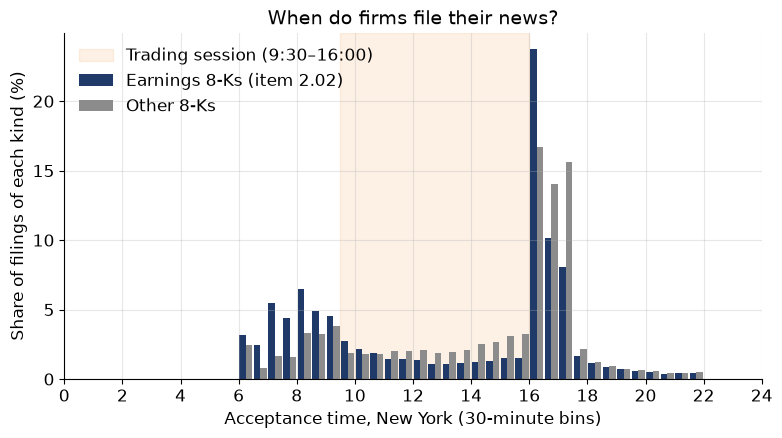

In [ ]:
windows = session_windows(f"{STUDY_START_YEAR}-01-01", str(study["date"].max().date()))
assigned = assign_sessions(filings, windows)
fig = plot_filing_times(filing_time_profile(assigned))
timing_summary(assigned)

**Takeaway:** News is a night-time activity. From 2003, **73.9 %** of 8-Ks and **80.2 %** of earnings 8-Ks are accepted outside the trading session. Earnings cluster in two windows: **42 %** between 16:00 and 17:30, right after the close, and **31 %** between 6:00 and 9:30, before the open. Only one earnings 8-K in five arrives while investors can trade. The suspect had the opportunity.

## IV.3 Is the timing right? A placebo check

A **covered** stock-day is a stock-day of a verified issuer, after its first EDGAR filing. A covered day is **quiet** when the issuer filed nothing at all (8-K, amendment, or filing without a recorded time) in the five sessions $t-2$ to $t+2$. This excludes news leaking before the filing and late reactions, and it only needs filing **dates**, so quiet days are defined over the whole study period 1998–2020. The night / day split of individual filings needs acceptance **times**, so it is used from 2003 only.

Before using the flags, we check that they mean what we think. Each covered stock-day is labelled: **no 8-K**, **8-K in the night only**, or **8-K during the day only**. If the timestamps and the session assignment are correct, a night 8-K should enlarge the **overnight** move but not the intraday one, and a day 8-K the reverse. Mean absolute returns from 2003, in basis points (1 bp = 0.01 %):

In [ ]:
panel = build_news_panel(stocks, identity, assigned, windows)
timed = panel[panel["timed"]]
print(f"{len(panel):,} covered stock-days ({len(panel) / len(stocks):.1%} of study stock-days), {panel['ticker'].nunique():,} stocks, "
      f"{panel['quiet'].mean():.1%} quiet. From {TIMED_START_YEAR}: {timed['news_night'].mean():.2%} have a night 8-K, "
      f"{timed['news_day'].mean():.2%} a day 8-K")
timing_validation(panel)

10,485,622 covered stock-days (73.9% of study stock-days), 4,194 stocks, 81.4% quiet. From 2003: 3.46% have a night 8-K, 1.14% a day 8-K


,|r_night| (bp),|r_day| (bp),n
kind,,,
no 8-K,66.400002,151.300003,8653201
night 8-K only,181.300003,243.800003,309014
day 8-K only,109.699997,201.000000,98992


**Takeaway:** Night filings behave as expected: a night 8-K multiplies the mean absolute overnight move by **2.7** (181 bp against 66 bp). Day filings are less clean: they raise the intraday move by a third (201 against 151 bp) but also the overnight move (110 against 66 bp), because a firm often issues its press release before the open and files the 8-K later in the day. This is why the main test relies on a ±2-session quiet window rather than on the exact split.

## IV.4 Does the crime survive without news?

We build daily equal-weighted portfolios from the covered stocks, as in Part II, for three groups: **all** covered stock-days and **quiet** stock-days (1998–2020), and **news** stock-days (an 8-K in that session's night or day, 2003–2020). Night and day returns of a group come from the same stock-days, so the gap is not a composition effect.

In [ ]:
news_ports = news_portfolios(panel)
annualised_means(news_ports)

,night (%),day (%),mean stocks per date
all,10.07,2.44,1872.66
news,13.20,-4.17,95.00
quiet,9.39,3.14,1524.85


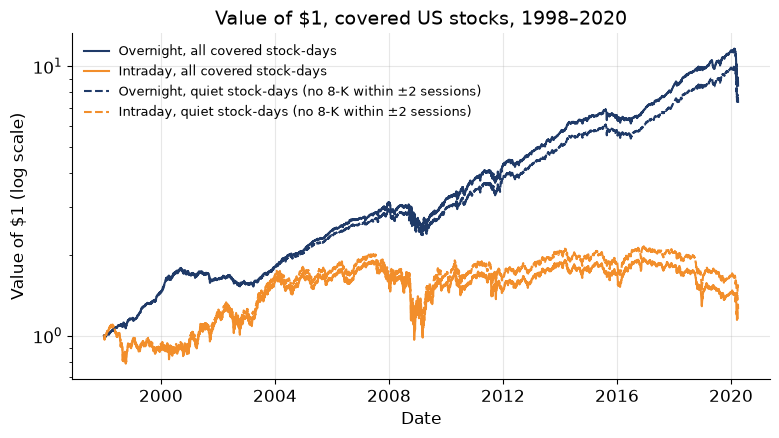

In [ ]:
fig = plot_news_wealth(news_paths(news_ports), f"Value of $1, covered US stocks, {STUDY_START_YEAR}–2020")

**Takeaway:** Removing news barely changes the picture. Over 1998–2020, \$1 invested in covered stocks only overnight became **\$8.48**, and **\$7.31** when only quiet stock-days are kept; intraday, it became \$1.27 and \$1.50. The quiet night still earns **9.4 %** a year against **3.1 %** for the quiet day. Quiet stock-days are 81 % of covered stock-days, and they carry the night's advantage on their own.

**Statistical test.** The same two tests as Part II: the night-indicator regression with standard errors clustered by date, and a block bootstrap (21-day blocks) of the daily night − day gap.

,stock-days,dates,gap annualised (%),CI low (clustered),CI high (clustered),p-value,CI low (bootstrap),CI high (bootstrap)
all covered,10483138,5598,7.639,0.199,15.079,0.044,1.33,15.27
quiet (no 8-K within ±2 sessions),8536101,5598,6.246,-1.070,13.562,0.094,-0.07,13.80
news (8-K that session),412469,4342,17.370,6.929,27.810,0.001,7.23,28.03


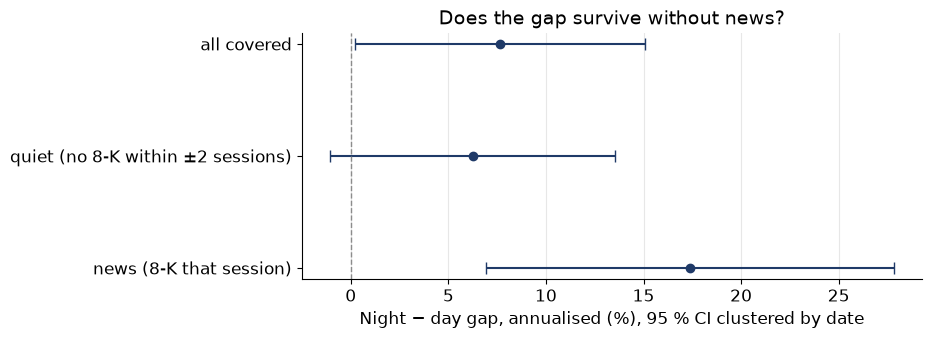

In [ ]:
gap_tests = quiet_gap_tests(news_ports)
fig = plot_gap_tests(gap_tests)
gap_tests

**Takeaway:** On covered stocks the gap is **7.64 %** a year (clustered 95 % CI [0.20, 15.08], p = 0.044). Without any filing nearby it is **6.25 %** ([−1.07, 13.56], p = 0.094; bootstrap [−0.07, 13.80]). Removing news lowers the estimate by about a fifth, and its interval now just includes zero. News stock-days show a larger gap (17.4 %, p = 0.001), but they are only 4 % of stock-days.

**Where does the overnight return come from?** Pooled over covered stock-days from 2003, each type's share of observations and share of the summed return. If news were the culprit, nights with an 8-K would carry a share of the summed overnight return far above their share of nights.

In [ ]:
news_decomposition(panel)

,observations,share of observations (%),mean (bp),share of summed return (%)
night with 8-K,313477,3.46,3.72,3.35
other night,8752209,96.54,3.85,96.65
day with 8-K,103455,1.14,1.74,NaN
other day,8962231,98.86,-0.10,NaN


**Takeaway:** Nights with an 8-K are **3.5 %** of covered nights and carry **3.4 %** of the summed overnight return: their mean (3.7 bp) is the same as that of other nights (3.9 bp). If news were the culprit, they would carry far more than their share. They do move prices much more (IV.3), but up and down in roughly equal measure.

## IV.5 What does a news night do to a stock?

A firm-level regression separates earnings 8-Ks from other 8-Ks, with **date fixed effects** (every market-wide move is removed by demeaning within each date):

$$r^{\text{night}}_{i,t} = a_t + b_1\, \text{earnings}_{i,t} + b_2\, \text{other 8-K}_{i,t} + \varepsilon_{i,t}$$

Standard errors are clustered two ways, by date and by stock. We estimate it for the signed return (does news earn more on average?) and for the absolute return (does news move prices?), in bp per stock-night.

In [ ]:
news_regression(panel, 'night')

coef (bp)   CI low  CI high  p-value  observations
outcome   regressor                                                       
r_night   earnings 8-K     -1.557   -5.409    2.296    0.428       9065686
          other 8-K         1.498    0.160    2.835    0.028       9065686
|r_night| earnings 8-K    255.296  247.002  263.589    0.000       9065686
          other 8-K        38.655   36.223   41.087    0.000       9065686

**Takeaway:** News moves prices but does not pay. An earnings 8-K in the night raises the absolute overnight move by **255 bp**, another 8-K by **39 bp** (both p < 0.001). The signed effect is **−1.6 bp** for earnings (p = 0.43) and **+1.5 bp** for other 8-Ks (p = 0.028), against a mean overnight return of about 4 bp. News adds volatility to the night, not drift.

**Over time.** Gap of the all and quiet portfolios in three periods: before EDGAR recorded filing times (1998–2002), before the 2008 crisis (2003–2007) and after it (2008–2020):

In [ ]:
quiet_gap_by_period(news_ports)

gap annualised (%)  CI low  CI high  p-value  dates
period    group                                                     
1998–2002 all                 4.842  -8.048   17.732    0.462   1256
          quiet               3.853  -8.935   16.642    0.555   1256
2003–2007 all                 7.025  -4.109   18.159    0.216   1258
          quiet               5.716  -5.245   16.677    0.307   1258
2008–2020 all                 9.029  -2.559   20.616    0.127   3084
          quiet               7.436  -3.935   18.807    0.200   3084

**Takeaway:** No sub-period is significant on its own, since splitting the sample widens every interval. Unlike SPY in Part II, the stock gap does not fade after 2008: the point estimate grows from **4.8 %** (1998–2002) to **7.0 %** and **9.0 %**. The quiet portfolio stays 1.0 to 1.6 points below in each period, so news explains a similarly small share of the gap throughout.

## Conclusion

**Verdict for P2: news is not the main culprit.**

- **Opportunity (IV.2):** 74 % of 8-Ks and 80 % of earnings 8-Ks arrive outside trading hours, so firm news does land at night.
- **No motive (IV.4):** keeping only stock-days with no filing within two sessions, the gap falls from 7.6 % to 6.2 % a year. Nights with an 8-K carry 3.4 % of the summed overnight return for 3.5 % of nights.
- **Volatility, not drift (IV.5):** an earnings 8-K adds 255 bp to the absolute overnight move but nothing significant to its mean.
- **Who carries the crime (IV.1):** the gap is small among firms still listed under the same ticker (3.5 %) and large among firms delisted or renamed since 2020 (18.3 %) and foreign filers (20.9 %).

The quiet gap is only borderline significant (p = 0.094), so news may explain part of the crime; it cannot explain most of it.

**Limits of this chapter.** 8-Ks are firm filings, not all news: analyst reports, press articles and macroeconomic releases (inflation and jobs reports come out at 8:30, during the night) are missed, so a quiet stock-day is quiet in filings only. A press release can precede its 8-K by minutes or hours; the ±2-session window protects the main test but not the night / day split of single filings. Verified issuers are US filers whose identity we could confirm, on top of the dataset's survivorship bias. Firms choose when to file, so all results are associations, not causal effects.

## Next steps for P3

1. **Separate earnings from other news.** Repeat the portfolio test for earnings and non-earnings 8-Ks, and vary the quiet window (±1 and ±5 sessions) and the quality filter.
2. **Look at the stocks the test cannot see.** Foreign filers carry a large gap; their US night overlaps their home market's trading day, as for the foreign ETFs excluded in Part II.
3. **Add macroeconomic news.** FOMC, CPI and jobs-report dates also arrive overnight and could explain the portfolio-level gap that firm filings do not.
4. **Share the news flags.** `build_news_panel` gives the crowd chapter volume spikes without any 8-K (attention without information), and the proof chapter the news days of a look-alike ticker's famous twin.

*References.* Cliff, M., Cooper, M. J. and Gulen, H. (2008). Return differences between trading and non-trading hours: Like night and day. Working paper, Virginia Tech. Frazzini, A. and Lamont, O. A. (2007). The earnings announcement premium and trading volume. NBER Working Paper 13090.

# Part V: The Crowd Suspect (preliminary results)

The third suspect is **the crowd**. Many individual investors do not follow the market live. When a company draws public attention, through an article, social media or television, they place their buy orders in the evening or before the open. These orders are executed together at the open and push the opening price up: an **overnight gain**. During the session, better-informed traders see that the price is too high and sell: an **intraday loss**. We call this pattern the **hangover**.

**Prediction.** After a burst of attention, the next overnight return should be above its normal level, and the next intraday return below its normal level.

**Roadmap.** V.1 defines an attention measure from trading volume. V.2 measures returns around attention spikes. V.3 checks whether the effect grows with the size of the spike. V.4 reports the feasibility test of Google Trends, a more direct attention measure for P3.

## V.1 Measuring attention: abnormal volume

We measure attention with **abnormal volume**, which needs no external data:

$$\text{abn\_volume}_t = \frac{\text{volume}_t}{\frac{1}{20}\sum_{s=1}^{20} \text{volume}_{t-s}}$$

The baseline is the mean volume of the **previous** 20 trading days of the same ticker, so a spike does not inflate its own baseline. The first 20 days of each ticker, and days with a zero baseline, are left undefined. A day is an **attention spike** when abnormal volume is above a threshold, 3 in the main analysis; we also test 2 and 5.

Abnormal volume is a relative measure: it compares each stock with its own recent level. In a market-wide crisis, volume rises for every stock at once and individual spikes are harder to detect. For example, Apple's abnormal volume stays close to 1 throughout March 2020, although its volume was very high.

In [ ]:
prices = abnormal_volume(prices, threshold=3)
{t: int((prices["abn_volume"] > t).sum()) for t in [2, 3, 5]}

{2: 2557980, 3: 1190238, 5: 490604}

Over the whole dataset, before any filter, there are about 2.6 million spike days at threshold 2, 1.2 million at threshold 3 and 0.5 million at threshold 5. Many come from small, rarely traded stocks, where a few extra trades are enough to multiply volume; the quality filter below removes them.

## V.2 Returns around attention spikes

We run an **event study**. Day 0 is the spike day, and day *k* is the *k*-th trading day of the same ticker after (*k* > 0) or before (*k* < 0) the spike. For each day from −5 to +5 we average the overnight and intraday returns across all spikes from 1998 onwards.

The volume spike happens *during* the session of day 0. The night the hypothesis is about is therefore the night **into day +1**, and the reversal is the intraday return of day +1.

**Sample.** We use the main quality filter of Part I (`FILTERS["liquidity"]`) and also remove stale opens (`open_equals_prev_close`, `open_equals_close`). Without the stale-open flags, more than half of the returns around spikes are exactly zero and the median is uninformative. Flagged rows are blanked rather than removed, so that day *k* remains the *k*-th trading day of the ticker.

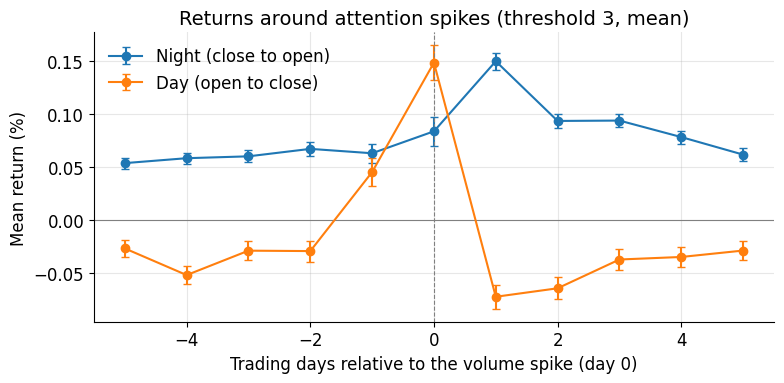

In [ ]:
flags = FILTERS["liquidity"] + ["open_equals_prev_close", "open_equals_close"]
result = event_study(prices, drop_flags=flags)
fig = plot_event_study(result, stat="mean", title="Returns around attention spikes (threshold 3, mean)")

Before the spike, overnight returns are positive (+0.06%) and intraday returns negative (-0.04%): this is the crime of Part II. On the night after the spike (day +1), the overnight return jumps to +0.149%, about 2.5 times its normal level, and the intraday return falls to -0.07%, about twice as negative as usual. Both effects fade over the following days. The 95% confidence intervals at day +1 do not overlap with the pre-spike levels. This is the hangover pattern predicted by the crowd hypothesis.

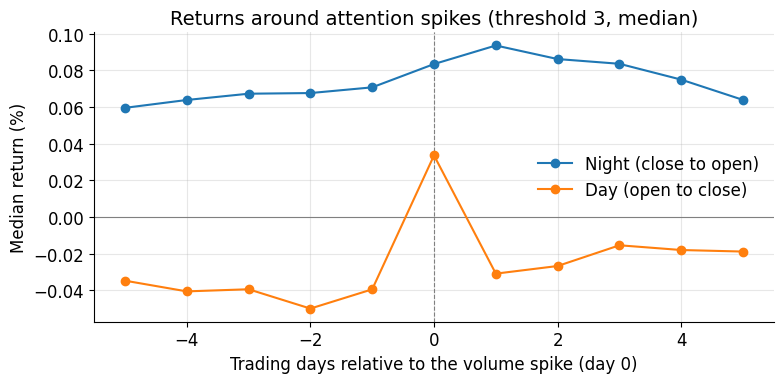

In [ ]:
fig = plot_event_study(result, stat="median", title="Returns around attention spikes (threshold 3, median)")

The median confirms the overnight part: the typical stock opens higher after a spike (+0.09% at day +1, against +0.07% before). The intraday part is not confirmed: the median intraday return at day +1 is not lower than before the spike. The average intraday reversal therefore comes from a subset of events with large drops, not from the typical event.

## V.3 Does the effect grow with attention?

If attention drives the pattern, larger spikes should produce a larger hangover: a dose-response relationship. We repeat the event study with thresholds 2 and 5.

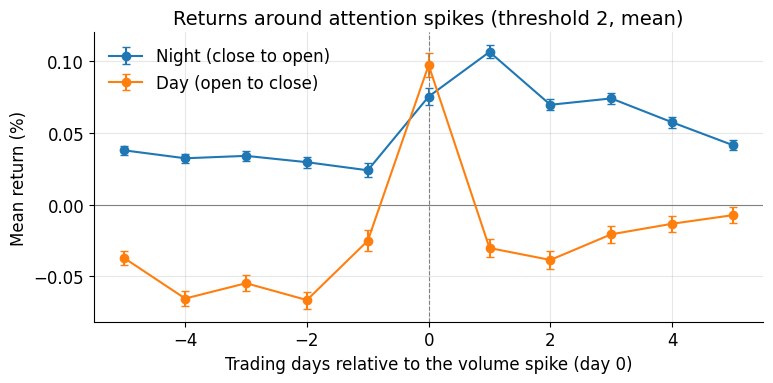

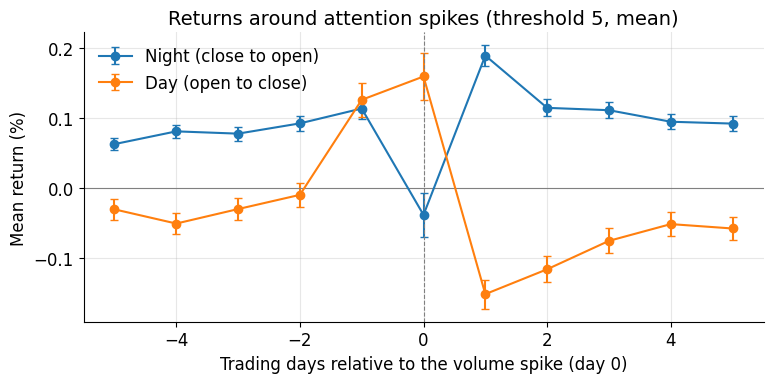

In [ ]:
for t in [2, 5]:
    res = event_study(abnormal_volume(prices, threshold=t), drop_flags=flags)
    fig = plot_event_study(res, stat="mean", title=f"Returns around attention spikes (threshold {t}, mean)")

| Threshold | Night +1 (before the spike) | Day +1 (before the spike) |
|---|---|---|
| 2 | +0.11% (+0.03%) | -0.03% (-0.06%) |
| 3 | +0.15% (+0.06%) | -0.07% (-0.04%) |
| 5 | +0.19% (+0.08%) | -0.15% (-0.03%) |

The hangover grows with the size of the spike. At threshold 2, the overnight gain is present but there is no intraday reversal; at threshold 5, both are large. This dose-response pattern is consistent with attention driving the effect, and explains the median result of V.2: the reversal is concentrated in the largest spikes.

The largest spikes also show signs of news. At threshold 5, the night before the spike (day 0) is negative (-0.04%) and the intraday return of day −1 is already high (+0.13%): many of these spikes follow overnight news, or news that starts a day early.

## V.4 Google Trends: feasibility

Google search interest measures public attention more directly than volume. We tested it with `pytrends` on ten large companies over January–March 2020:

- **Search terms.** The company name alone ("Apple") measures interest in the brand and barely reacts to the COVID crash. The term "*X* stock" captures interest in the stock: it drops every weekend, peaks around Apple's earnings release at the end of January, and rises sharply during the crash.
- **Resolution.** Daily data are only available on short windows; a two-year window returns weekly data. Each window is rescaled from 0 to 100, so values can only be compared within a window.
- **Coverage.** Google Trends starts in 2004, and financial search terms have low volume for smaller companies.
- **Access.** `pytrends` is unofficial. Ten consecutive requests with a two-second pause were not blocked, but larger volumes may be.

**Decision: go, limited.** For P3 we will request short daily windows around volume spikes for about 30 large companies, using "*X* stock", and measure attention relative to the window's average. If access fails at scale, abnormal volume remains our attention measure.

## Conclusion

**Verdict for P2: the crowd remains a credible suspect.**

- **Overnight gain (V.2):** after an attention spike, the next overnight return is well above its normal level, in both the mean and the median.
- **Intraday reversal (V.2):** on average, the next intraday return is below its normal level, but the typical event shows no reversal; the average effect comes from a subset of events.
- **Dose-response (V.3):** both the overnight gain and the intraday reversal grow with the size of the spike.

The suspect is not convicted. A volume spike often comes with news, so this analysis shows that attention **comes with** a hangover, not that attention alone **causes** it. The effect is also small, about 0.1 percentage point per night, so it is unclear whether it could be exploited after transaction costs.

## Next steps for P3

- **Separate news from attention:** split spikes into those with and without an 8-K filing (Part IV), and use confused tickers as a natural experiment (Part VI).
- **Google Trends:** measure search interest around spikes for about 30 large companies.
- **Market-adjusted returns:** subtract the market's overnight and intraday returns of the same day, since spikes cluster on market-wide days.
- **Correct confidence intervals:** spikes on the same date are not independent, so the current intervals are too narrow; we will cluster them by date.
- **Which events reverse:** compare the reversal across spike size, stock size and liquidity.
- **Transaction costs:** check whether the effect survives realistic trading costs.